# **New York City Yellow Taxi Data**

## Objective
In this case study you will be learning exploratory data analysis (EDA) with the help of a dataset on yellow taxi rides in New York City. This will enable you to understand why EDA is an important step in the process of data science and machine learning.

## **Problem Statement**
As an analyst at an upcoming taxi operation in NYC, you are tasked to use the 2023 taxi trip data to uncover insights that could help optimise taxi operations. The goal is to analyse patterns in the data that can inform strategic decisions to improve service efficiency, maximise revenue, and enhance passenger experience.

## Tasks
You need to perform the following steps for successfully completing this assignment:
1. Data Loading
2. Data Cleaning
3. Exploratory Analysis: Bivariate and Multivariate
4. Creating Visualisations to Support the Analysis
5. Deriving Insights and Stating Conclusions

---

**NOTE:** The marks given along with headings and sub-headings are cumulative marks for those particular headings/sub-headings.<br>

The actual marks for each task are specified within the tasks themselves.

For example, marks given with heading *2* or sub-heading *2.1* are the cumulative marks, for your reference only. <br>

The marks you will receive for completing tasks are given with the tasks.

Suppose the marks for two tasks are: 3 marks for 2.1.1 and 2 marks for 3.2.2, or
* 2.1.1 [3 marks]
* 3.2.2 [2 marks]

then, you will earn 3 marks for completing task 2.1.1 and 2 marks for completing task 3.2.2.


---

## Data Understanding
The yellow taxi trip records include fields capturing pick-up and drop-off dates/times, pick-up and drop-off locations, trip distances, itemized fares, rate types, payment types, and driver-reported passenger counts.

The data is stored in Parquet format (*.parquet*). The dataset is from 2009 to 2024. However, for this assignment, we will only be using the data from 2023.

The data for each month is present in a different parquet file. You will get twelve files for each of the months in 2023.

The data was collected and provided to the NYC Taxi and Limousine Commission (TLC) by technology providers like vendors and taxi hailing apps. <br>

You can find the link to the TLC trip records page here: https://www.nyc.gov/site/tlc/about/tlc-trip-record-data.page

###  Data Description
You can find the data description here: [Data Dictionary](https://www.nyc.gov/assets/tlc/downloads/pdf/data_dictionary_trip_records_yellow.pdf)

**Trip Records**



|Field Name       |description |
|:----------------|:-----------|
| VendorID | A code indicating the TPEP provider that provided the record. <br> 1= Creative Mobile Technologies, LLC; <br> 2= VeriFone Inc. |
| tpep_pickup_datetime | The date and time when the meter was engaged.  |
| tpep_dropoff_datetime | The date and time when the meter was disengaged.   |
| Passenger_count | The number of passengers in the vehicle. <br> This is a driver-entered value. |
| Trip_distance | The elapsed trip distance in miles reported by the taximeter. |
| PULocationID | TLC Taxi Zone in which the taximeter was engaged |
| DOLocationID | TLC Taxi Zone in which the taximeter was disengaged |
|RateCodeID |The final rate code in effect at the end of the trip.<br> 1 = Standard rate <br> 2 = JFK <br> 3 = Newark <br>4 = Nassau or Westchester <br>5 = Negotiated fare <br>6 = Group ride |
|Store_and_fwd_flag |This flag indicates whether the trip record was held in vehicle memory before sending to the vendor, aka “store and forward,” because the vehicle did not have a connection to the server.  <br>Y= store and forward trip <br>N= not a store and forward trip |
|Payment_type| A numeric code signifying how the passenger paid for the trip. <br> 1 = Credit card <br>2 = Cash <br>3 = No charge <br>4 = Dispute <br>5 = Unknown <br>6 = Voided trip |
|Fare_amount| The time-and-distance fare calculated by the meter. <br>Extra Miscellaneous extras and surcharges.  Currently, this only includes the 0.50 and 1 USD rush hour and overnight charges. |
|MTA_tax |0.50 USD MTA tax that is automatically triggered based on the metered rate in use. |
|Improvement_surcharge | 0.30 USD improvement surcharge assessed trips at the flag drop. The improvement surcharge began being levied in 2015. |
|Tip_amount |Tip amount – This field is automatically populated for credit card tips. Cash tips are not included. |
| Tolls_amount | Total amount of all tolls paid in trip.  |
| total_amount | The total amount charged to passengers. Does not include cash tips. |
|Congestion_Surcharge |Total amount collected in trip for NYS congestion surcharge. |
| Airport_fee | 1.25 USD for pick up only at LaGuardia and John F. Kennedy Airports|

Although the amounts of extra charges and taxes applied are specified in the data dictionary, you will see that some cases have different values of these charges in the actual data.

**Taxi Zones**

Each of the trip records contains a field corresponding to the location of the pickup or drop-off of the trip, populated by numbers ranging from 1-263.

These numbers correspond to taxi zones, which may be downloaded as a table or map/shapefile and matched to the trip records using a join.

This is covered in more detail in later sections.

---

## **1** Data Preparation

<font color = red>[5 marks]</font> <br>

### Import Libraries

In [1]:
# Import warnings
import warnings
warnings.filterwarnings('ignore')


In [2]:
# Import the libraries you will be using for analysis
# Import the libraries you will be using for analysis
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


In [3]:
# Recommended versions
# numpy version: 1.26.4
# pandas version: 2.2.2
# matplotlib version: 3.10.0
# seaborn version: 0.13.2

# Check versions
print("numpy version:", np.__version__)
print("pandas version:", pd.__version__)
print("matplotlib version:", plt.matplotlib.__version__)
print("seaborn version:", sns.__version__)

numpy version: 2.4.6
pandas version: 3.0.5
matplotlib version: 3.11.2
seaborn version: 0.13.2


### **1.1** Load the dataset
<font color = red>[5 marks]</font> <br>

You will see twelve files, one for each month.

To read parquet files with Pandas, you have to follow a similar syntax as that for CSV files.

`df = pd.read_parquet('file.parquet')`

In [ ]:
# Try loading one file

df = pd.read_parquet('C:/content/drive/MyDrive/Colab Notebooks/trip_records/2023-1.parquet')
df.info()

<class 'pandas.DataFrame'>
Index: 3041714 entries, 0 to 3066765
Data columns (total 19 columns):
 #   Column                 Dtype         
---  ------                 -----         
 0   VendorID               int64         
 1   tpep_pickup_datetime   datetime64[us]
 2   tpep_dropoff_datetime  datetime64[us]
 3   passenger_count        float64       
 4   trip_distance          float64       
 5   RatecodeID             float64       
 6   store_and_fwd_flag     str           
 7   PULocationID           int64         
 8   DOLocationID           int64         
 9   payment_type           int64         
 10  fare_amount            float64       
 11  extra                  float64       
 12  mta_tax                float64       
 13  tip_amount             float64       
 14  tolls_amount           float64       
 15  improvement_surcharge  float64       
 16  total_amount           float64       
 17  congestion_surcharge   float64       
 18  airport_fee            float64       


In [5]:
df.shape
df.head()
newOne=df.copy()
newOne['pickup_date'] = newOne['tpep_pickup_datetime'].dt.date
newOne['pickup_hour'] = newOne['tpep_pickup_datetime'].dt.hour
newOne.sample(2)


,VendorID,tpep_pickup_datetime,tpep_dropoff_datetime,passenger_count,trip_distance,RatecodeID,store_and_fwd_flag,PULocationID,DOLocationID,payment_type,...,extra,mta_tax,tip_amount,tolls_amount,improvement_surcharge,total_amount,congestion_surcharge,airport_fee,pickup_date,pickup_hour
3027259,2,2023-01-15 10:26:15,2023-01-15 10:35:41,NaN,2.10,NaN,NaN,239,75,0,...,0.0,0.5,2.00,0.0,1.0,20.22,NaN,NaN,2023-01-15,10
1012033,2,2023-01-12 11:07:51,2023-01-12 11:25:04,1.0,1.96,1.0,N,236,161,1,...,0.0,0.5,3.65,0.0,1.0,23.95,2.5,0.0,2023-01-12,11


How many rows are there? Do you think handling such a large number of rows is computationally feasible when we have to combine the data for all twelve months into one?

To handle this, we need to sample a fraction of data from each of the files. How to go about that? Think of a way to select only some portion of the data from each month's file that accurately represents the trends.

#### Sampling the Data
> One way is to take a small percentage of entries for pickup in every hour of a date. So, for all the days in a month, we can iterate through the hours and select 5% values randomly from those. Use `tpep_pickup_datetime` for this. Separate date and hour from the datetime values and then for each date, select some fraction of trips for each of the 24 hours.

To sample data, you can use the `sample()` method. Follow this syntax:

```Python
# sampled_data is an empty DF to keep appending sampled data of each hour
# hour_data is the DF of entries for an hour 'X' on a date 'Y'

sample = hour_data.sample(frac = 0.05, random_state = 42)
# sample 0.05 of the hour_data
# random_state is just a seed for sampling, you can define it yourself

sampled_data = pd.concat([sampled_data, sample]) # adding data for this hour to the DF
```

This *sampled_data* will contain 5% values selected at random from each hour.

Note that the code given above is only the part that will be used for sampling and not the complete code required for sampling and combining the data files.

Keep in mind that you sample by date AND hour, not just hour. (Why?)

---

**1.1.1** <font color = red>[5 marks]</font> <br>
Figure out how to sample and combine the files.

**Note:** It is not mandatory to use the method specified above. While sampling, you only need to make sure that your sampled data represents the overall data of all the months accurately.

In [6]:
# Sample the data
# It is recommmended to not load all the files at once to avoid memory overload

In [ ]:
# from google.colab import drive
# drive.mount('/content/drive')
import os
list_files = os.listdir('/content/drive/MyDrive/Colab Notebooks/trip_records')
print(list_files)
# print length to confirm that there are 12 files
print(f'Total files : {len(list_files)}')

['2023-1.parquet', '2023-10.parquet', '2023-11.parquet', '2023-12.parquet', '2023-2.parquet', '2023-3.parquet', '2023-4.parquet', '2023-5.parquet', '2023-6.parquet', '2023-7.parquet', '2023-8.parquet', '2023-9.parquet', 'nyc_taxi_2023_sampled.csv']
Total files : 13


In [ ]:
# Take a small percentage of entries from each hour of every date.
# Iterating through the monthly data:
#   read a month file -> day -> hour: append sampled data -> move to next hour -> move to next day after 24 hours -> move to next month file
# Create a single dataframe for the year combining all the monthly data

# Select the folder having data files
import os

# Select the folder having data files
os.chdir('/content/drive/MyDrive/Colab Notebooks/trip_records')

# Create a list of all the twelve files to read
file_list = os.listdir()

# initialise an empty dataframe
df = pd.DataFrame()


# iterate through the list of files and sample one by one:
for file_name in file_list:
    try:
        # file path for the current file
        file_path = os.path.join(os.getcwd(), file_name)

        # Reading the current file
        monthly_records_df = pd.read_parquet(file_path)

        # Create date and hour columns
        monthly_records_df['pickup_date'] = monthly_records_df['tpep_pickup_datetime'].dt.date
        monthly_records_df['pickup_hour'] = monthly_records_df['tpep_pickup_datetime'].dt.hour

        # We will store the sampled data for the current date in this df by appending the sampled data from each hour to this
        # After completing iteration through each date, we will append this data to the final dataframe.
        sampled_data = pd.DataFrame()

        # Loop through dates and then loop through every hour of each date
        for pick_up_date in monthly_records_df['pickup_date'].unique():
            daily_records_df = monthly_records_df[monthly_records_df['pickup_date'] == pick_up_date]
            if len(daily_records_df) > 0:
                for pick_up_hour in daily_records_df['pickup_hour'].unique():
                    hourly_records_df = daily_records_df[daily_records_df['pickup_hour'] == pick_up_hour]
                    if len(hourly_records_df) > 0:
                        # Sample 5% of the records for the current hour and append to the sampled_data dataframe
                        sampled_hourly_records_df = hourly_records_df.sample(frac=0.05, random_state=8)
                        sampled_data = pd.concat([sampled_data, sampled_hourly_records_df], ignore_index=True)

        # Concatenate the sampled data of all the dates to a single dataframe
        df = pd.concat([df, sampled_data], ignore_index=True)
        print(f"File : {file_name} | sampled rows : {len(sampled_data)}")
    except Exception as e:
        print(f"Error reading file {file_name}: {e}")

    print(f"Total sampled rows : {len(df)}")


File : 2023-1.parquet | sampled rows : 152087
Total sampled rows : 152087
File : 2023-10.parquet | sampled rows : 174255
Total sampled rows : 326342
File : 2023-11.parquet | sampled rows : 165133
Total sampled rows : 491475
File : 2023-12.parquet | sampled rows : 166709
Total sampled rows : 658184
File : 2023-2.parquet | sampled rows : 168696
Total sampled rows : 826880
File : 2023-3.parquet | sampled rows : 163786
Total sampled rows : 990666
File : 2023-4.parquet | sampled rows : 139641
Total sampled rows : 1130307
File : 2023-5.parquet | sampled rows : 144458
Total sampled rows : 1274765
File : 2023-6.parquet | sampled rows : 162910
Total sampled rows : 1437675
File : 2023-7.parquet | sampled rows : 174068
Total sampled rows : 1611743
File : 2023-8.parquet | sampled rows : 143782
Total sampled rows : 1755525
File : 2023-9.parquet | sampled rows : 140875
Total sampled rows : 1896400
Error reading file nyc_taxi_2023_sampled.csv: Could not open Parquet input source '<Buffer>': Parquet m

After combining the data files into one DataFrame, convert the new DataFrame to a CSV or parquet file and store it to use directly.

Ideally, you can try keeping the total entries to around 250,000 to 300,000.

In [9]:
# Store the df in csv/parquet

df_sampled = df.sample(n=min(300000, len(df)), random_state=8)
# remove the pickup_date and pickup_hour columns as they are not needed for further analysis and temporarily added
df_sampled.drop(columns=['pickup_date', 'pickup_hour'], inplace=True)
df_sampled.to_csv('nyc_taxi_2023_sampled.csv', index=False)
print(f"Sampled dataset with {len(df_sampled)} rows saved to 'nyc_taxi_2023_sampled.csv'")

Sampled dataset with 300000 rows saved to 'nyc_taxi_2023_sampled.csv'


## **2** Data Cleaning
<font color = red>[30 marks]</font> <br>

Now we can load the new data directly.

In [10]:
# Load the new data file
df=pd.read_csv('nyc_taxi_2023_sampled.csv')

In [11]:
df.head()

,VendorID,tpep_pickup_datetime,tpep_dropoff_datetime,passenger_count,trip_distance,RatecodeID,store_and_fwd_flag,PULocationID,DOLocationID,payment_type,fare_amount,extra,mta_tax,tip_amount,tolls_amount,improvement_surcharge,total_amount,congestion_surcharge,airport_fee,Airport_fee
0,2,2023-03-30 14:46:39,2023-03-30 14:53:56,1.0,1.14,1.0,N,140,263,1,9.3,0.00,0.5,1.33,0.00,1.0,14.63,2.5,NaN,0.00
1,1,2023-06-23 17:21:36,2023-06-23 17:24:59,1.0,1.00,1.0,N,170,107,1,6.5,5.00,0.5,2.60,0.00,1.0,15.60,2.5,NaN,0.00
2,1,2023-07-16 10:29:34,2023-07-16 11:12:25,1.0,17.00,2.0,N,132,48,1,70.0,4.25,0.5,16.45,6.55,1.0,98.75,2.5,NaN,1.75
3,2,2023-05-31 11:13:21,2023-05-31 11:15:53,2.0,0.44,1.0,N,170,234,1,4.4,0.00,0.5,1.68,0.00,1.0,10.08,2.5,NaN,0.00
4,2,2023-06-04 20:51:26,2023-06-04 21:32:10,2.0,18.12,2.0,N,132,262,1,70.0,0.00,0.5,1.00,0.00,1.0,76.75,2.5,NaN,1.75


In [12]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 300000 entries, 0 to 299999
Data columns (total 20 columns):
 #   Column                 Non-Null Count   Dtype  
---  ------                 --------------   -----  
 0   VendorID               300000 non-null  int64  
 1   tpep_pickup_datetime   300000 non-null  str    
 2   tpep_dropoff_datetime  300000 non-null  str    
 3   passenger_count        290214 non-null  float64
 4   trip_distance          300000 non-null  float64
 5   RatecodeID             290214 non-null  float64
 6   store_and_fwd_flag     290214 non-null  str    
 7   PULocationID           300000 non-null  int64  
 8   DOLocationID           300000 non-null  int64  
 9   payment_type           300000 non-null  int64  
 10  fare_amount            300000 non-null  float64
 11  extra                  300000 non-null  float64
 12  mta_tax                300000 non-null  float64
 13  tip_amount             300000 non-null  float64
 14  tolls_amount           300000 non-null  float64

#### **2.1** Fixing Columns
<font color = red>[10 marks]</font> <br>

Fix/drop any columns as you seem necessary in the below sections

**2.1.1** <font color = red>[2 marks]</font> <br>

Fix the index and drop unnecessary columns

In [13]:
# check for columns having missing values percentage and drop them if required
missing_percentage = (df.isna().sum() / len(df)) * 100
print(missing_percentage[missing_percentage > 0].sort_values(ascending=False))
# nothing to delete even though airport_fee has 90% missing values, we will keep it for now as it is a monetary critical column and can be ignored for analysis.


airport_fee             92.055333
Airport_fee             11.206667
RatecodeID               3.262000
passenger_count          3.262000
congestion_surcharge     3.262000
store_and_fwd_flag       3.262000
dtype: float64


In [14]:
# Fix the index and drop any columns that are not needed
df.reset_index(drop=True, inplace=True)
# drop the 'store_and_fwd_flag' column as it is not needed for further analysis
df.drop(columns = ['store_and_fwd_flag'], inplace=True)


In [15]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 300000 entries, 0 to 299999
Data columns (total 19 columns):
 #   Column                 Non-Null Count   Dtype  
---  ------                 --------------   -----  
 0   VendorID               300000 non-null  int64  
 1   tpep_pickup_datetime   300000 non-null  str    
 2   tpep_dropoff_datetime  300000 non-null  str    
 3   passenger_count        290214 non-null  float64
 4   trip_distance          300000 non-null  float64
 5   RatecodeID             290214 non-null  float64
 6   PULocationID           300000 non-null  int64  
 7   DOLocationID           300000 non-null  int64  
 8   payment_type           300000 non-null  int64  
 9   fare_amount            300000 non-null  float64
 10  extra                  300000 non-null  float64
 11  mta_tax                300000 non-null  float64
 12  tip_amount             300000 non-null  float64
 13  tolls_amount           300000 non-null  float64
 14  improvement_surcharge  300000 non-null  float64

**2.1.2** <font color = red>[3 marks]</font> <br>
There are two airport fee columns. This is possibly an error in naming columns. Let's see whether these can be combined into a single column.

In [16]:
# Combine the two airport fee columns

# select both columns
airport_fee_cols = df[['airport_fee', 'Airport_fee']]

# Take the row-wise max, ignoring NaNs (so a non-null value wins over a null one,
# and the higher value wins when both are non-null)
combined_fee = airport_fee_cols.max(axis=1, skipna=True)

#  where both were null, the max is itself NaN, so fill that with 0
combined_fee = combined_fee.fillna(0)

# Step 4: assign back and drop the duplicate column
df['airport_fee'] = combined_fee
df.drop(columns=['Airport_fee'], inplace=True)


In [17]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 300000 entries, 0 to 299999
Data columns (total 18 columns):
 #   Column                 Non-Null Count   Dtype  
---  ------                 --------------   -----  
 0   VendorID               300000 non-null  int64  
 1   tpep_pickup_datetime   300000 non-null  str    
 2   tpep_dropoff_datetime  300000 non-null  str    
 3   passenger_count        290214 non-null  float64
 4   trip_distance          300000 non-null  float64
 5   RatecodeID             290214 non-null  float64
 6   PULocationID           300000 non-null  int64  
 7   DOLocationID           300000 non-null  int64  
 8   payment_type           300000 non-null  int64  
 9   fare_amount            300000 non-null  float64
 10  extra                  300000 non-null  float64
 11  mta_tax                300000 non-null  float64
 12  tip_amount             300000 non-null  float64
 13  tolls_amount           300000 non-null  float64
 14  improvement_surcharge  300000 non-null  float64

**2.1.3** <font color = red>[5 marks]</font> <br>
Fix columns with negative (monetary) values

In [18]:
# check where values of fare amount are negative
negative_fare_df = df[df['fare_amount'] < 0]
'No rows have fare with negative amount' if len(negative_fare_df) == 0 else f'Total rows: {len(negative_fare_df)}'


'No rows have fare with negative amount'

Did you notice something different in the `RatecodeID` column for above records?

In [19]:
# Analyse RatecodeID for the negative fare amounts
negative_fare_df = df[df['fare_amount'] < 0]
if len(negative_fare_df) == 0:
    print('No rows have fare with negative amount so no RatecodeID analysis is needed')
else:
    # print the value counts of RatecodeID for the negative fare amounts
    negative_fare_df['RatecodeID'].value_counts()


No rows have fare with negative amount so no RatecodeID analysis is needed


In [20]:
# Find which columns have negative values

# All numeric columns having monetary values
monetary_columns = [
    'fare_amount',
    'extra',
    'mta_tax',
    'improvement_surcharge',
    'tip_amount',
    'tolls_amount',
    'total_amount',
    'congestion_surcharge',
    'airport_fee'
]
# Get the count of negative values for each numeric column
negative_cols_counts = (df[monetary_columns] < 0).sum()
# print the columns with negative values and their counts in descending order
negative_cols_counts[negative_cols_counts > 0].sort_values(ascending=False)


improvement_surcharge    15
total_amount             15
mta_tax                  11
congestion_surcharge      8
airport_fee               1
dtype: int64

In [21]:
# fix these negative values

# Delete ALL rows where ANY of these columns have negative values as total amount calculated is sum of these columns and if any of them is negative, the total amount will be incorrect. So we will delete all rows where any of these columns have negative values.
# Other option could be delete all rows having total_amount negative value but that will not fix the issue of negative values in other columns which are part of total_amount calculation. And clipping other column negative values to 0 would require additional logic to ensure total_amount remains correct.

columns_to_check = ['improvement_surcharge', 'total_amount', 'mta_tax', 'congestion_surcharge', 'airport_fee']

negatives_values_mask = (df[columns_to_check] < 0).any(axis=1)
total_rows_deleted = negatives_values_mask.sum()

# Delete rows where any of these columns are negative
df = df[~negatives_values_mask]

print(f'Total rows deleted: {total_rows_deleted}')

# Verify no negative values remain in these columns
negative_check = (df[columns_to_check] < 0).sum()
print(f'Negative values remaining:\n{negative_check}')


Total rows deleted: 15
Negative values remaining:
improvement_surcharge    0
total_amount             0
mta_tax                  0
congestion_surcharge     0
airport_fee              0
dtype: int64


In [22]:
df.info()

<class 'pandas.DataFrame'>
Index: 299985 entries, 0 to 299999
Data columns (total 18 columns):
 #   Column                 Non-Null Count   Dtype  
---  ------                 --------------   -----  
 0   VendorID               299985 non-null  int64  
 1   tpep_pickup_datetime   299985 non-null  str    
 2   tpep_dropoff_datetime  299985 non-null  str    
 3   passenger_count        290199 non-null  float64
 4   trip_distance          299985 non-null  float64
 5   RatecodeID             290199 non-null  float64
 6   PULocationID           299985 non-null  int64  
 7   DOLocationID           299985 non-null  int64  
 8   payment_type           299985 non-null  int64  
 9   fare_amount            299985 non-null  float64
 10  extra                  299985 non-null  float64
 11  mta_tax                299985 non-null  float64
 12  tip_amount             299985 non-null  float64
 13  tolls_amount           299985 non-null  float64
 14  improvement_surcharge  299985 non-null  float64
 15 

### **2.2** Handling Missing Values
<font color = red>[10 marks]</font> <br>

**2.2.1**  <font color = red>[2 marks]</font> <br>
Find the proportion of missing values in each column




In [23]:
# Find the proportion of missing values in each column
missing_values_proportion = (df.isna().sum() / len(df)) * 100
missing_values_proportion.sort_values(ascending=False)


RatecodeID               3.262163
passenger_count          3.262163
congestion_surcharge     3.262163
VendorID                 0.000000
tpep_pickup_datetime     0.000000
tpep_dropoff_datetime    0.000000
PULocationID             0.000000
DOLocationID             0.000000
payment_type             0.000000
trip_distance            0.000000
fare_amount              0.000000
extra                    0.000000
tip_amount               0.000000
mta_tax                  0.000000
tolls_amount             0.000000
improvement_surcharge    0.000000
total_amount             0.000000
airport_fee              0.000000
dtype: float64

**2.2.2**  <font color = red>[3 marks]</font> <br>
Handling missing values in `passenger_count`

In [24]:
# Display the rows with null values
# Impute NaN values in 'passenger_count'

# Check for null values in passenger_count
null_passenger_counts = df[df['passenger_count'].isna()]
print(f'Number of passengers with null count: {len(null_passenger_counts)}')
if len(null_passenger_counts) > 0:
    print('Sample rows having null passenger_count : ')
    print(null_passenger_counts.head(3))
    # Impute null values with the median passenger_count
    median_passenger_count = df['passenger_count'].median()
    df['passenger_count'] = df['passenger_count'].fillna(median_passenger_count, inplace=True)
    print(f"Number of passengers with null count after imputation: {df['passenger_count'].isna().sum()}")


Number of passengers with null count: 9786
Sample rows having null passenger_count : 
    VendorID tpep_pickup_datetime tpep_dropoff_datetime  passenger_count  \
39         2  2023-11-07 08:38:00   2023-11-07 08:52:00              NaN   
57         1  2023-09-02 01:02:39   2023-09-02 01:16:23              NaN   
63         2  2023-10-21 05:45:07   2023-10-21 05:53:24              NaN   

    trip_distance  RatecodeID  PULocationID  DOLocationID  payment_type  \
39           1.73         NaN           262           163             0   
57           0.00         NaN            79           263             0   
63           1.84         NaN           170           140             0   

    fare_amount  extra  mta_tax  tip_amount  tolls_amount  \
39        14.51    0.0      0.5        3.33           0.0   
57        20.25    0.0      0.5        0.00           0.0   
63        11.88    0.0      0.5        0.00           0.0   

    improvement_surcharge  total_amount  congestion_surcharge  

Did you find zeroes in passenger_count? Handle these.

In [25]:
# Handle records having passenger_count as zero.
passenger_having_zero_counts=df[df['passenger_count'] == 0]
print('Passenger count having zero values', len(passenger_having_zero_counts))

if len(passenger_having_zero_counts) > 0:
    # Impute zero values with the median passenger_count
    median_passenger_count = df['passenger_count'].median()
    df['passenger_count'] = df['passenger_count'].replace(0, median_passenger_count)
    print(f"Number of passengers with zero count after imputation: {len(df[df['passenger_count'] == 0])}")


Passenger count having zero values 4737
Number of passengers with zero count after imputation: 0


**2.2.3**  <font color = red>[2 marks]</font> <br>
Handle missing values in `RatecodeID`

In [26]:
# Fix missing values in 'RatecodeID'

null_ratecode = df[df['RatecodeID'].isna()]
print(f"Number of RateCodeId having null values: {len(null_ratecode)}")

if len(null_ratecode) > 0:
    #impute null values with the mode of RatecodeID as this is a categorical column and mode is the most frequent value
    mode_ratecode = df['RatecodeID'].mode()[0]
    df['RatecodeID'] = df['RatecodeID'].fillna(mode_ratecode)
    print(f"Number of RatecodeID having null values after imputation: {df['RatecodeID'].isna().sum()}")


Number of RateCodeId having null values: 9786
Number of RatecodeID having null values after imputation: 0


**2.2.4**  <font color = red>[3 marks]</font> <br>
Impute NaN in `congestion_surcharge`

In [27]:
# handle null values in congestion_surcharge

null_congestion_surcharge = df[df['congestion_surcharge'].isna()]
print(f"Number of congestion surcharge having null values: {len(null_congestion_surcharge)}")

if len(null_congestion_surcharge) > 0:
    # Impute null values with 0 (since congestion surcharge is conditional, null likely means not applied)
    df['congestion_surcharge'] = df['congestion_surcharge'].fillna(0)
    print(f"Number of congestion_surcharge having null values after imputation: {df['congestion_surcharge'].isna().sum()}")


Number of congestion surcharge having null values: 9786
Number of congestion_surcharge having null values after imputation: 0


Are there missing values in other columns? Did you find NaN values in some other set of columns? Handle those missing values below.

In [28]:
# Handle any remaining missing values
df.isna().sum()
# No more column has missing values. All missing values have been handled appropriately.

VendorID                 0
tpep_pickup_datetime     0
tpep_dropoff_datetime    0
passenger_count          0
trip_distance            0
RatecodeID               0
PULocationID             0
DOLocationID             0
payment_type             0
fare_amount              0
extra                    0
mta_tax                  0
tip_amount               0
tolls_amount             0
improvement_surcharge    0
total_amount             0
congestion_surcharge     0
airport_fee              0
dtype: int64

 **2.3** Handling Outliers
<font color = red>[10 marks]</font> <br>

Before we start fixing outliers, let's perform outlier analysis.

In [29]:
# Describe the data and check if there are any potential outliers present
# Check for potential out of place values in various columns
df.describe()

,VendorID,passenger_count,trip_distance,RatecodeID,PULocationID,DOLocationID,payment_type,fare_amount,extra,mta_tax,tip_amount,tolls_amount,improvement_surcharge,total_amount,congestion_surcharge,airport_fee
count,299985.000000,299985.000000,299985.000000,299985.000000,299985.000000,299985.000000,299985.000000,299985.000000,299985.000000,299985.000000,299985.000000,299985.000000,299985.000000,299985.000000,299985.000000,299985.000000
mean,1.736954,1.372572,3.707962,1.615937,165.192360,163.825738,1.164712,19.870538,1.580996,0.495331,3.557064,0.594820,0.999124,28.944865,2.235903,0.137554
std,0.444883,0.862958,129.092765,7.283466,63.990771,69.869981,0.505525,18.288237,1.825868,0.048188,4.052785,2.184034,0.027193,22.820864,0.768438,0.456717
min,1.000000,1.000000,0.000000,1.000000,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,1.000000,1.000000,1.050000,1.000000,132.000000,113.000000,1.000000,9.300000,0.000000,0.500000,1.000000,0.000000,1.000000,15.960000,2.500000,0.000000
50%,2.000000,1.000000,1.790000,1.000000,162.000000,162.000000,1.000000,13.500000,1.000000,0.500000,2.850000,0.000000,1.000000,21.000000,2.500000,0.000000
75%,2.000000,1.000000,3.410000,1.000000,234.000000,234.000000,1.000000,22.600000,2.500000,0.500000,4.450000,0.000000,1.000000,31.050000,2.500000,0.000000
max,6.000000,8.000000,70457.900000,99.000000,265.000000,265.000000,4.000000,900.000000,14.250000,0.800000,220.000000,94.750000,1.000000,901.000000,2.500000,1.750000


**2.3.1**  <font color = red>[10 marks]</font> <br>
Based on the above analysis, it seems that some of the outliers are present due to errors in registering the trips. Fix the outliers.

Some points you can look for:
- Entries where `trip_distance` is nearly 0 and `fare_amount` is more than 300
- Entries where `trip_distance` and `fare_amount` are 0 but the pickup and dropoff zones are different (both distance and fare should not be zero for different zones)
- Entries where `trip_distance` is more than 250  miles.
- Entries where `payment_type` is 0 (there is no payment_type 0 defined in the data dictionary)

These are just some suggestions. You can handle outliers in any way you wish, using the insights from above outlier analysis.

How will you fix each of these values? Which ones will you drop and which ones will you replace?

First, let us remove 7+ passenger counts as there are very less instances.

In [30]:
# remove passenger_count > 6
print(f"Records with passenger_count > 6: {len(df[df['passenger_count'] > 6])}")
# Check rows before delete
print(df.shape)
# Remove rows where passenger_count > 6
df = df[df['passenger_count'] <= 6]
# Check rows after delete
print(df.shape)


Records with passenger_count > 6: 3
(299985, 18)
(299982, 18)


In [31]:
# Continue with outlier handling

# 1. Trip distance ≈ 0 with fare_amount > 300
# Will drop the records as they are likely data entry errors (e.g., fare amount entered incorrectly for a very short trip)
high_fare_outliers = df[(df['trip_distance'] < 0.5) & (df['fare_amount'] > 300)]
print(f'High fare outliers: {len(high_fare_outliers)} rows')
# Drop high fare outliers
print(f"Records before dropping high fare outliers: {len(df)}")
df = df[~((df['trip_distance'] < 0.5) & (df['fare_amount'] > 300))]
print(f"Records after dropping high fare outliers: {len(df)}")


High fare outliers: 8 rows
Records before dropping high fare outliers: 299982
Records after dropping high fare outliers: 299974


In [32]:

# 2. Zero trip_distance AND zero fare_amount with different pickup and dropoff zones
zero_distance_fare_with_diff_zone_outliers = df[(df['trip_distance'] == 0) & (df['fare_amount'] == 0) &  (df['PULocationID'] != df['DOLocationID'])]
print(f'Zero distance & zero fare with different zones outliers: {len(zero_distance_fare_with_diff_zone_outliers)} rows')
# Drop these outliers as they are contradictory (different zones should have distance/fare)
print(f"Records before dropping zero distance & zero fare with different zones outliers: {len(df)}")
df = df[~((df['trip_distance'] == 0) & (df['fare_amount'] == 0) &  (df['PULocationID'] != df['DOLocationID']))]
print(f"Records after dropping zero distance & zero fare with different zones outliers: {len(df)}")


Zero distance & zero fare with different zones outliers: 10 rows
Records before dropping zero distance & zero fare with different zones outliers: 299974
Records after dropping zero distance & zero fare with different zones outliers: 299964


In [33]:

# 3. Trip distance > 250 miles (unrealistic for NYC)
higher_trip_distance_outliers = df[df['trip_distance'] > 250]
print(f'Higher trip distance outliers: {len(higher_trip_distance_outliers)} rows')
# Drop these outliers as they are unrealistic for NYC taxi trips
print(f"Records before dropping higher trip distance outliers: {len(df)}")
df = df[df['trip_distance'] <= 250]
print(f"Records after dropping higher trip distance outliers: {len(df)}")


Higher trip distance outliers: 3 rows
Records before dropping higher trip distance outliers: 299964
Records after dropping higher trip distance outliers: 299961


In [34]:
# 4. Invalid payment_type (valid values are 1,2,3,4,5,6)
invalid_payment_type_outliers =df[~df['payment_type'].isin([1,2,3,4,5,6])]
print(f'Invalid payment type outliers: {len(invalid_payment_type_outliers)} rows')
# Drop these outliers as they are invalid payment types (not in data dictionary)
print(f"Records before dropping invalid payment type outliers: {len(df)}")
df = df[df['payment_type'].isin([1,2,3,4,5,6])]
print(f"Records after dropping invalid payment type outliers: {len(df)}")


Invalid payment type outliers: 9784 rows
Records before dropping invalid payment type outliers: 299961
Records after dropping invalid payment type outliers: 290177


In [35]:

# Zero fare trips (trip completed but no charge). Trip distance > 0 and payment_type is either 1 (Credit card) or 2 (Cash). These are valid trips but with zero fare. This could be due to free trips, test rides, or errors in fare calculation. We will keep these records for analysis but will note them as potential outliers.
zero_fare_outliers = df[(df['fare_amount'] == 0) & (df['trip_distance'] > 0) & (df['payment_type'].isin([1,2]))]
count_zero_fare = zero_fare_outliers.shape[0]
print(f'Zero fare trips: {count_zero_fare} rows')


Zero fare trips: 16 rows


In [36]:

# Do any columns need standardising?

print(df.describe().T[['min', 'max', 'mean', 'std']])

# Not standardising the columns as the scale differences are manageable and we have already removed extreme outliers.

# Extreme outliers have already been removed during cleaning:
# Removed passenger_count > 6 (very rare instances)
# Removed trip_distance > 250 miles (unrealistic for NYC)
# Removed high fare outliers (distance < 0.5 & fare > 300)
# Removed invalid payment types and ratecode IDs
# Without extreme outliers, scale differences are manageable


                       min     max        mean        std
VendorID               1.0    2.00    1.740582   0.438316
passenger_count        1.0    6.00    1.385079   0.874393
trip_distance          0.0   93.50    3.454668   4.547441
RatecodeID             1.0   99.00    1.636198   7.402393
PULocationID           1.0  265.00  165.360428  63.664993
DOLocationID           1.0  265.00  164.068713  69.803783
payment_type           1.0    4.00    1.203962   0.465667
fare_amount            0.0  569.30   19.769297  18.224115
extra                  0.0   14.25    1.628856   1.832701
mta_tax                0.0    0.80    0.495378   0.047951
tip_amount             0.0  220.00    3.584036   4.069917
tolls_amount           0.0   94.75    0.594929   2.184282
improvement_surcharge  0.0    1.00    0.999367   0.023192
total_amount           0.0  615.68   28.904182  22.839555
congestion_surcharge   0.0    2.50    2.311417   0.660224
airport_fee            0.0    1.75    0.142198   0.463650


In [37]:
df.columns.tolist()

['VendorID',
 'tpep_pickup_datetime',
 'tpep_dropoff_datetime',
 'passenger_count',
 'trip_distance',
 'RatecodeID',
 'PULocationID',
 'DOLocationID',
 'payment_type',
 'fare_amount',
 'extra',
 'mta_tax',
 'tip_amount',
 'tolls_amount',
 'improvement_surcharge',
 'total_amount',
 'congestion_surcharge',
 'airport_fee']

# **3.1** General EDA: Finding Patterns and Trends
<font color = red>[40 marks]</font> <br>

**3.1.1** <font color = red>[3 marks]</font> <br>
Categorise the varaibles into Numerical or Categorical.
* `VendorID`:
* `tpep_pickup_datetime`:
* `tpep_dropoff_datetime`:
* `passenger_count`:
* `trip_distance`:
* `RatecodeID`:
* `PULocationID`:
* `DOLocationID`:
* `payment_type`:
* `pickup_hour`:
* `trip_duration`:


The following monetary parameters belong in the same category, is it categorical or numerical?


* `fare_amount`
* `extra`
* `mta_tax`
* `tip_amount`
* `tolls_amount`
* `improvement_surcharge`
* `total_amount`
* `congestion_surcharge`
* `airport_fee`


Categorise the varaibles into Numerical or Categorical.
* `VendorID`: **Categorical** 
* `tpep_pickup_datetime`: **DateTime** 
* `tpep_dropoff_datetime`: **DateTime** 
* `passenger_count`: **Numerical - Discrete** 
* `trip_distance`: **Numerical - Continuous** 
* `RatecodeID`: **Categorical** 
* `PULocationID`: **Categorical** 
* `DOLocationID`: **Categorical** 
* `payment_type`: *Categorical* 
* `pickup_hour`: **Numerical - Discrete** 
* `trip_duration`: **Numerical - Continuous** 


The following monetary parameters belong in the same category, is it categorical or numerical?


* `fare_amount`: **Numerical - Continuous**
* `extra`: **Numerical - Continuous**
* `mta_tax`: **Numerical - Continuous**
* `tip_amount`: **Numerical - Continuous**
* `tolls_amount`: **Numerical - Continuous**
* `improvement_surcharge`: **Numerical - Continuous**
* `total_amount`: **Numerical - Continuous**
* `congestion_surcharge`: **Numerical - Continuous**
* `airport_fee`: **Numerical - Continuous**

**Answer:** All monetary parameters are **Numerical - Continuous** values (measured in USD with decimal places). These are continuous because they can take any value within a range, not just fixed integers.


## Temporal Analysis

**3.1.2** <font color = red>[5 marks]</font> <br>
Analyse the distribution of taxi pickups by hours, days of the week, and months.

Busiest hour: 18:00 , total pickups : 20614
Slowest hour: 5:00 , total pickups : 1578
Average pickups per hour: 12090.708333333334


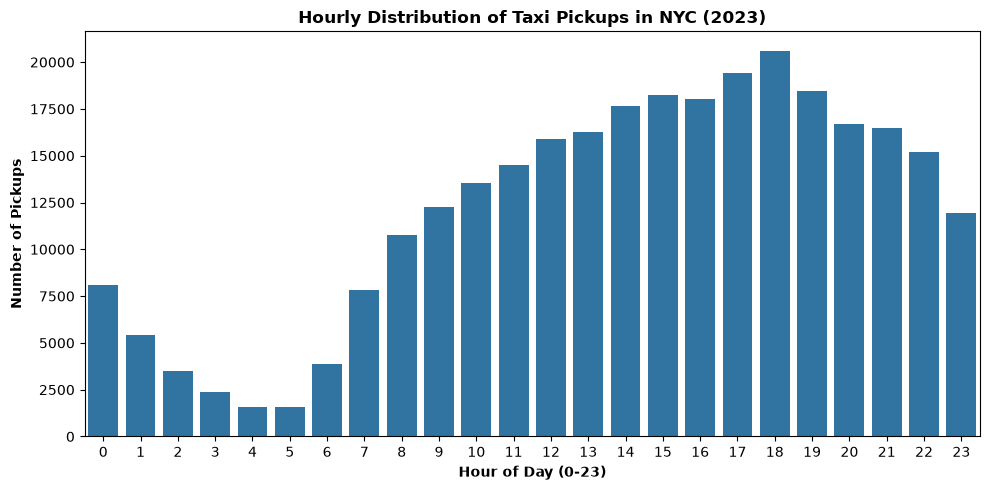

In [38]:
# Find and show the hourly trends in taxi pickups

# Convert tpep_pickup_datetime to datetime
df['tpep_pickup_datetime'] = pd.to_datetime(df['tpep_pickup_datetime'])
# Extract hour from pickup datetime
df['pickup_hour'] = df['tpep_pickup_datetime'].dt.hour
# Count trips per hour
hourly_pickups = df['pickup_hour'].value_counts().sort_index()

# Some statistics about hourly pickups
print(f'Busiest hour: {hourly_pickups.idxmax()}:00 , total pickups : {hourly_pickups.loc[hourly_pickups.idxmax()]}')
print(f'Slowest hour: {hourly_pickups.idxmin()}:00 , total pickups : {hourly_pickups.loc[hourly_pickups.idxmin()]}')
print(f'Average pickups per hour: {hourly_pickups.mean()}')

# Visualize hourly trends
plt.figure(figsize=(10,5))
sns.countplot(data=df,x='pickup_hour')
plt.xlabel('Hour of Day (0-23)', fontweight='bold')
plt.ylabel('Number of Pickups',  fontweight='bold')
plt.title('Hourly Distribution of Taxi Pickups in NYC (2023)', fontweight='bold')
plt.tight_layout()
plt.show()


Busiest day: Thursday , total pickups : 45546
Slowest day: Sunday , total pickups : 36084
Average pickups per day: 41453.857142857145


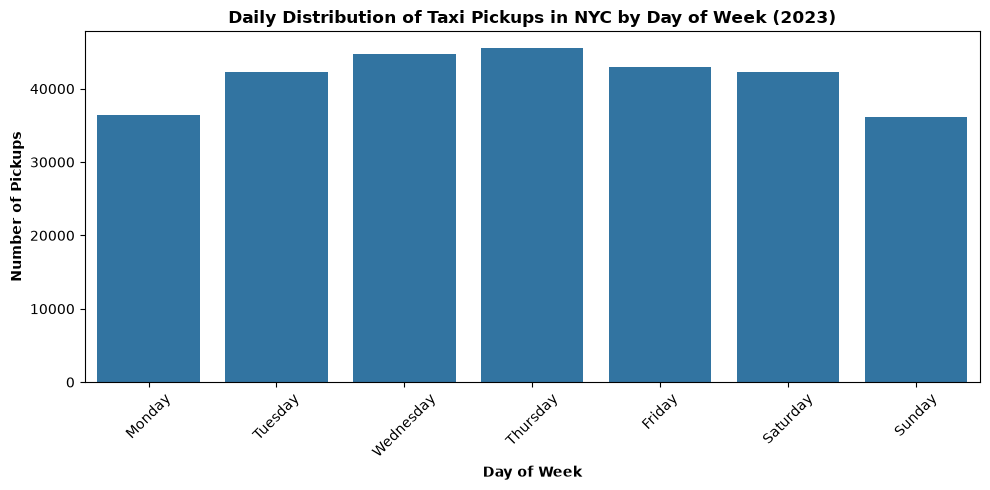

In [39]:
# Find and show the daily trends in taxi pickups (days of the week)

# Extract day of week from pickup datetime (0=Monday, 6=Sunday)
df['pickup_day_of_week'] = df['tpep_pickup_datetime'].dt.dayofweek
# Map day numbers to day names to a new column
day_names = {0: 'Monday', 1: 'Tuesday', 2: 'Wednesday', 3: 'Thursday', 4: 'Friday', 5: 'Saturday', 6: 'Sunday'}
df['pickup_day_name'] = df['pickup_day_of_week'].map(day_names)

# Count trips per day of week
daily_pickups = df['pickup_day_of_week'].value_counts().sort_index()

# Some statistics about daily pickups
print(f'Busiest day: {day_names[daily_pickups.idxmax()]} , total pickups : {daily_pickups.loc[daily_pickups.idxmax()]}')
print(f'Slowest day: {day_names[daily_pickups.idxmin()]} , total pickups : {daily_pickups.loc[daily_pickups.idxmin()]}')
print(f'Average pickups per day: {daily_pickups.mean()}')

# Visualize daily trends
plt.figure(figsize=(10,5))
day_order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']
sns.countplot(data=df, x='pickup_day_name', order=day_order)
plt.xlabel('Day of Week', fontweight='bold')
plt.ylabel('Number of Pickups', fontweight='bold')
plt.title('Daily Distribution of Taxi Pickups in NYC by Day of Week (2023)', fontweight='bold')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

Busiest month: 5 , total pickups : 26692
Slowest month: 9 , total pickups : 21329
Average pickups per month: 24181.416666666668


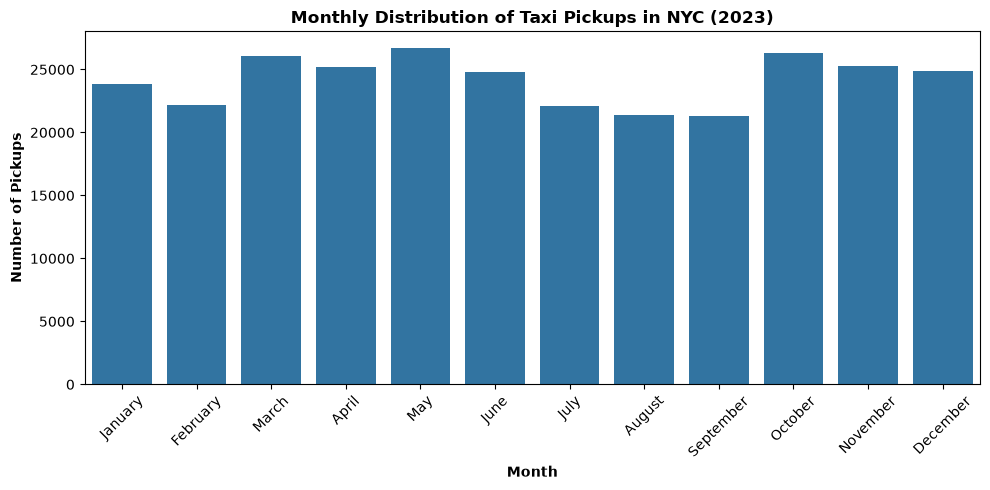

In [40]:
# Show the monthly trends in pickups

# Extract month from pickup datetime and assign to a new column
df['pickup_month'] = df['tpep_pickup_datetime'].dt.month
#  trips per month
monthly_pickups = df['pickup_month'].value_counts().sort_index()
# change df['pickup_month'] to month name like 1= jan and 12=dec
month_names = {1: 'January', 2: 'February', 3: 'March', 4: 'April', 5: 'May', 6: 'June', 7: 'July', 8: 'August', 9: 'September', 10: 'October', 11: 'November', 12: 'December'}
df['pickup_month_name'] = df['pickup_month'].map(month_names)

# Some statistics about monthly pickups
print(f'Busiest month: {monthly_pickups.idxmax()} , total pickups : {monthly_pickups.loc[monthly_pickups.idxmax()]}')
print(f'Slowest month: {monthly_pickups.idxmin()} , total pickups : {monthly_pickups.loc[monthly_pickups.idxmin()]}')
print(f'Average pickups per month: {monthly_pickups.mean()}')

# Visualize monthly trends
plt.figure(figsize=(10,5))
sns.countplot(data=df, x='pickup_month_name', order=list(month_names.values()))
plt.xlabel('Month', fontweight='bold')
plt.ylabel('Number of Pickups', fontweight='bold')
plt.title('Monthly Distribution of Taxi Pickups in NYC (2023)', fontweight='bold')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

##### Financial Analysis

Take a look at the financial parameters like `fare_amount`, `tip_amount`, `total_amount`, and also `trip_distance`. Do these contain zero/negative values?

fare_amount: Zero=67, Negative=0
tip_amount: Zero=64696, Negative=0
total_amount: Zero=36, Negative=0
trip_distance: Zero=3320, Negative=0


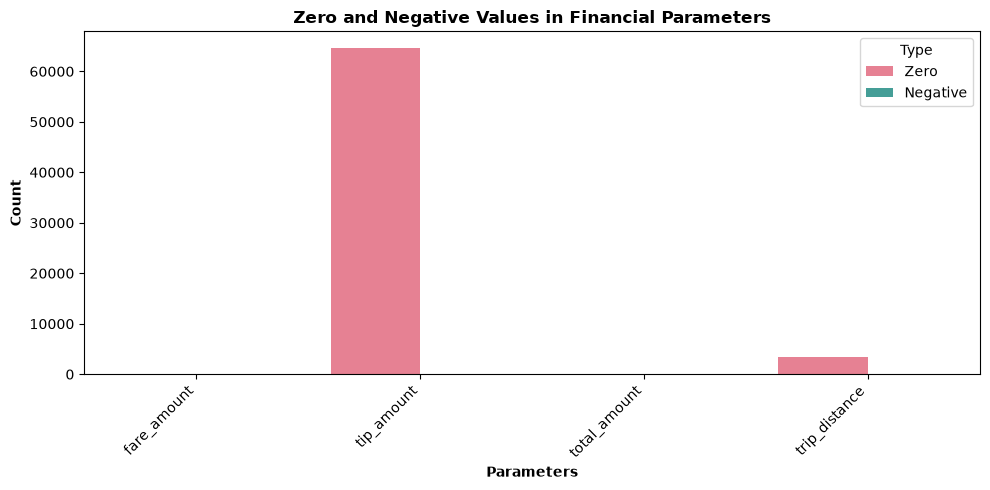

In [41]:
# Analyse zero and negative values
params = ['fare_amount', 'tip_amount', 'total_amount', 'trip_distance']
zero = [(df[p] == 0).sum() for p in params]
negative = [(df[p] < 0).sum() for p in params]

# Print counts
for p, z, n in zip(params, zero, negative):
    print(f"{p}: Zero={z}, Negative={n}")

# Create DataFrame for visualization
data = pd.DataFrame({
    'Parameters': params + params,
    'Count': zero + negative,
    'Type': ['Zero']*len(params) + ['Negative']*len(params)
})

# Grouped bar plot using seaborn
plt.figure(figsize=(10, 5))
sns.barplot(data=data, x='Parameters', y='Count', hue='Type', palette='husl')
plt.title('Zero and Negative Values in Financial Parameters', fontweight='bold')
plt.xlabel('Parameters', fontweight='bold')
plt.ylabel('Count', fontweight='bold')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

Do you think it is beneficial to create a copy DataFrame leaving out the zero values from these?

In [42]:
# Yes, create two DataFrames: Keep original df for overall analysis, and create filtered df_non_zero (excluding zero fares, distances, totals) for pricing/revenue # analysis. This lets us analyze both actual customer behavior and clean data patterns separately.

df_non_zero = df[(df['fare_amount'] != 0) & (df['trip_distance'] != 0) & (df['total_amount'] != 0)].copy()

**3.1.3** <font color=red>[2 marks]</font> <br>
Filter out zero values from the financial parameters.

**Note:** Zero distance indicates pickup and dropoff in the same zone. Should these be kept or removed?

In [43]:
# Create a df with non zero entries for the selected parameters.
# df_non_zero already created in a previous celldf_non_zero = df[(df['fare_amount'] != 0) & (df['trip_distance'] != 0) & (df['total_amount'] != 0)].copy()
# It excludes rows with zero fare_amount, trip_distance, or total_amount
print(f"Original data size: {len(df)}")
print(f"Non-zero data size: {len(df_non_zero)}")
print(f"Rows removed: {len(df) - len(df_non_zero)}")


Original data size: 290177
Non-zero data size: 286820
Rows removed: 3357


**3.1.4** <font color = red>[3 marks]</font> <br>
Analyse the monthly revenue (`total_amount`) trend

Highest revenue month: May - $772017.41
Lowest revenue month: February - $593590.3
Average monthly revenue: $688874.7000000001


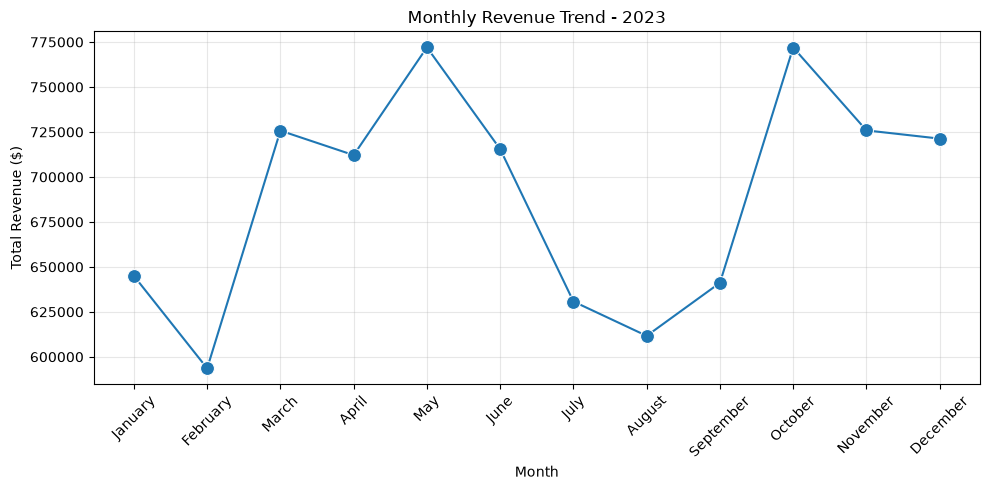

In [44]:
# Analyse the monthly revenue (total_amount) trend

# Group by month and calculate total revenue
monthly_revenue = df_non_zero.groupby('pickup_month')['total_amount'].agg(['sum', 'mean', 'count'])
monthly_revenue['month_name'] = monthly_revenue.index.map(month_names)

# Statistics
print(f'Highest revenue month: {month_names[monthly_revenue["sum"].idxmax()]} - ${monthly_revenue.loc[monthly_revenue["sum"].idxmax(), "sum"]}')
print(f'Lowest revenue month: {month_names[monthly_revenue["sum"].idxmin()]} - ${monthly_revenue.loc[monthly_revenue["sum"].idxmin(), "sum"]}')
print(f'Average monthly revenue: ${monthly_revenue["sum"].mean()}')

# Visualize with seaborn and matplotlib
plt.figure(figsize=(10, 5))
sns.lineplot(x=monthly_revenue.index, y=monthly_revenue['sum'], marker='o', markersize=10)
plt.xlabel('Month')
plt.ylabel('Total Revenue ($)')
plt.title('Monthly Revenue Trend - 2023')
plt.xticks(monthly_revenue.index, [month_names[m] for m in monthly_revenue.index], rotation=45)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

**3.1.5** <font color = red>[3 marks]</font> <br>
Show the proportion of each quarter of the year in the revenue

Q1: $1,964,287.19 (23.76%)
Q2: $2,199,585.93 (26.61%)
Q3: $1,883,526.18 (22.79%)
Q4: $2,219,097.10 (26.84%)


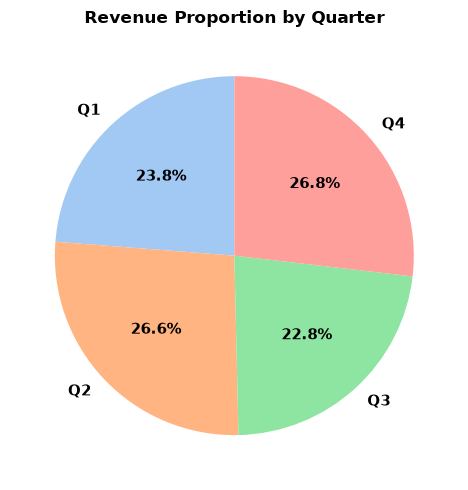

In [45]:
# Calculate proportion of each quarter

# Create quarter column using datetime
df_non_zero['quarter'] = df_non_zero['tpep_pickup_datetime'].dt.quarter

# Group by quarter and calculate total revenue
quarterly_revenue = df_non_zero.groupby('quarter')['total_amount'].sum().sort_index()
quarterly_revenue_percentage = (quarterly_revenue / quarterly_revenue.sum() * 100).round(2)

# Summary statistics
for quarter, revenue in quarterly_revenue.items():
    pct = quarterly_revenue_percentage[quarter]
    print(f"Q{quarter}: ${revenue:,.2f} ({pct}%)")

# PIE CHART - Best for showing proportions
plt.figure(figsize=(5, 5))
colors = sns.color_palette('pastel', len(quarterly_revenue))
plt.pie(quarterly_revenue, labels=[f'Q{q}' for q in quarterly_revenue.index], autopct='%1.1f%%',
        colors=colors, startangle=90, textprops={'fontsize': 11, 'weight': 'bold'})
plt.title('Revenue Proportion by Quarter', fontweight='bold')
plt.tight_layout()
plt.show()

**3.1.6** <font color = red>[3 marks]</font> <br>
Visualise the relationship between `trip_distance` and `fare_amount`. Also find the correlation value for these two.

**Hint:** You can leave out the trips with trip_distance = 0

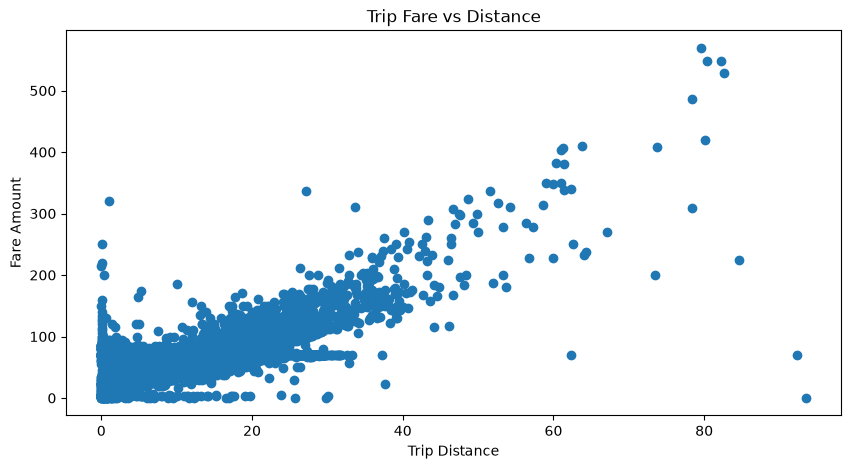

Correlation between trip distance and fare amount: 0.94


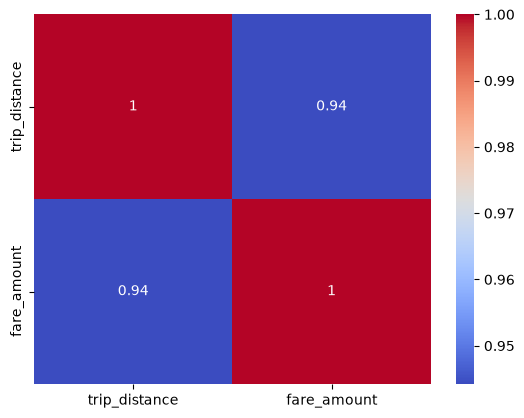

In [46]:
# Show how trip fare is affected by distance

trip_non_zero = df[df['trip_distance'] > 0]
plt.figure(figsize=(10, 5))
plt.scatter(trip_non_zero['trip_distance'], trip_non_zero['fare_amount'])
plt.xlabel('Trip Distance')
plt.ylabel('Fare Amount')
plt.title('Trip Fare vs Distance')
plt.show()

#find correlation between trip_distance and fare_amount
correlation = trip_non_zero['trip_distance'].corr(trip_non_zero['fare_amount'])
print(f"Correlation between trip distance and fare amount: {correlation:.2f}")

#show the correlation matrix for trip_distance, fare_amount
correlation_matrix = trip_non_zero[['trip_distance', 'fare_amount']].corr()
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm')
plt.show()

# trip_distance and fare_amount are positively correlated, When trip distance increases, fare amount tends to increase as well.

**3.1.7** <font color = red>[5 marks]</font> <br>
Find and visualise the correlation between:
1. `fare_amount` and trip duration (pickup time to dropoff time)
2. `fare_amount` and `passenger_count`
3. `tip_amount` and `trip_distance`

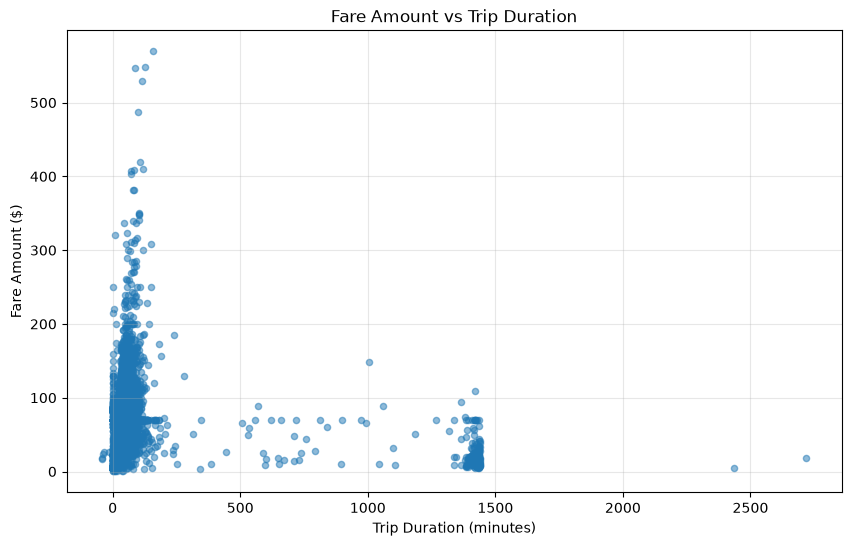

Correlation between trip duration and fare amount: 0.27


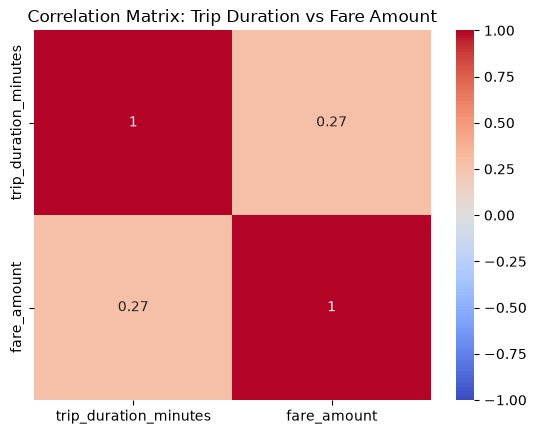

In [47]:
# Show relationship between fare and trip duration

# Convert datetime columns to proper datetime type
df_non_zero['tpep_dropoff_datetime'] = pd.to_datetime(df_non_zero['tpep_dropoff_datetime'])
df_non_zero['tpep_pickup_datetime'] = pd.to_datetime(df_non_zero['tpep_pickup_datetime'])

# Calculate trip duration in minutes
df_non_zero['trip_duration_minutes'] = (df_non_zero['tpep_dropoff_datetime'] - df_non_zero['tpep_pickup_datetime']).dt.total_seconds() / 60

# Scatter plot
plt.figure(figsize=(10, 6))
plt.scatter(df_non_zero['trip_duration_minutes'], df_non_zero['fare_amount'], alpha=0.5, s=20)
plt.xlabel('Trip Duration (minutes)')
plt.ylabel('Fare Amount ($)')
plt.title('Fare Amount vs Trip Duration')
plt.grid(True, alpha=0.3)
plt.show()

# Find correlation
correlation = df_non_zero['trip_duration_minutes'].corr(df_non_zero['fare_amount'])
print(f"Correlation between trip duration and fare amount: {correlation:.2f}")

# Correlation matrix and heatmap
correlation_matrix = df_non_zero[['trip_duration_minutes', 'fare_amount']].corr()
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', vmin=-1, vmax=1)
plt.title('Correlation Matrix: Trip Duration vs Fare Amount')
plt.show()
# Trip duration and fare amount show a weak positive correlation (0.27). While there is a tendency for fares to increase with longer trips, this relationship is modest and other factors (distance, traffic, surge pricing) likely have stronger influences on the final fare.

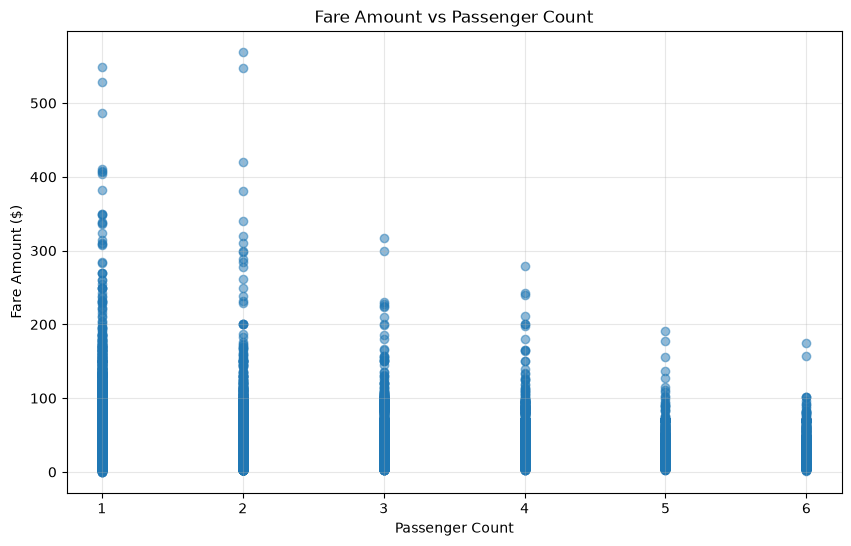

Correlation between passenger count and fare amount: 0.04


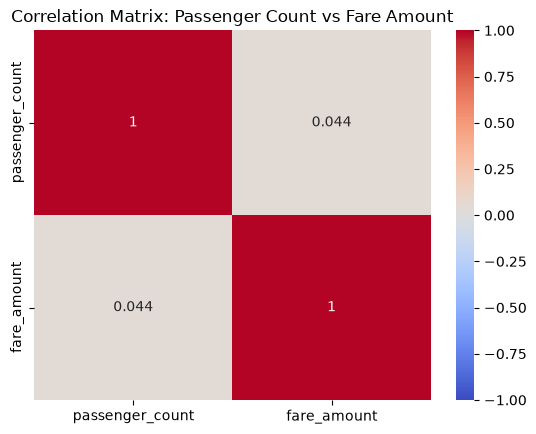

In [48]:
# Show relationship between fare and number of passengers

# Scatter plot
plt.figure(figsize=(10, 6))
plt.scatter(df_non_zero['passenger_count'], df_non_zero['fare_amount'], alpha=0.5)
plt.xlabel('Passenger Count')
plt.ylabel('Fare Amount ($)')
plt.title('Fare Amount vs Passenger Count')
plt.grid(True, alpha=0.3)
plt.show()

# Find correlation
correlation = df_non_zero['passenger_count'].corr(df_non_zero['fare_amount'])
print(f"Correlation between passenger count and fare amount: {correlation:.2f}")

# Correlation matrix and heatmap
correlation_matrix = df_non_zero[['passenger_count', 'fare_amount']].corr()
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', vmin=-1, vmax=1)
plt.title('Correlation Matrix: Passenger Count vs Fare Amount')
plt.show()
# There is virtually no correlation (0.04) between passenger count and fare amount. Passenger count has almost no impact on the fare amount charged

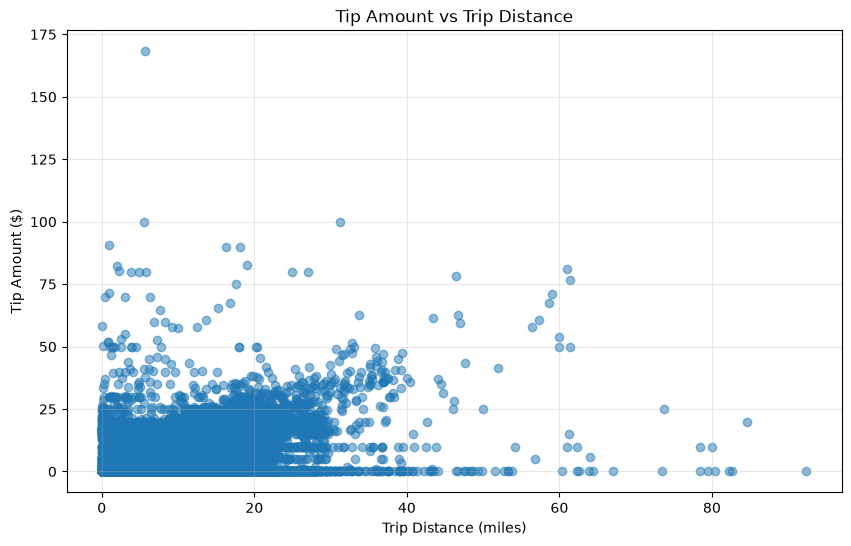

Correlation between trip distance and tip amount: 0.59


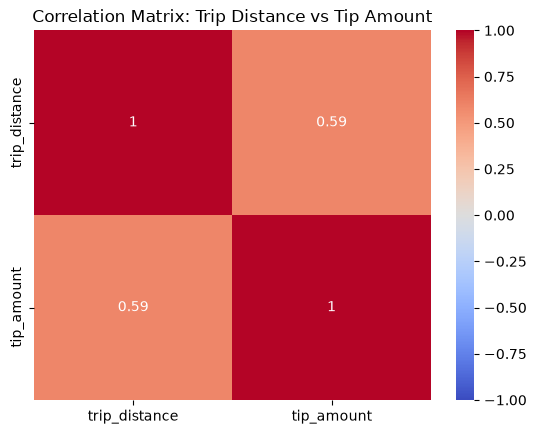

In [49]:
# Show relationship between tip and trip distance

# Scatter plot
plt.figure(figsize=(10, 6))
plt.scatter(df_non_zero['trip_distance'], df_non_zero['tip_amount'], alpha=0.5)
plt.xlabel('Trip Distance (miles)')
plt.ylabel('Tip Amount ($)')
plt.title('Tip Amount vs Trip Distance')
plt.grid(True, alpha=0.3)
plt.show()

# Find correlation
correlation = df_non_zero['trip_distance'].corr(df_non_zero['tip_amount'])
print(f"Correlation between trip distance and tip amount: {correlation:.2f}")

# Correlation matrix and heatmap
correlation_matrix = df_non_zero[['trip_distance', 'tip_amount']].corr()
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', vmin=-1, vmax=1)
plt.title('Correlation Matrix: Trip Distance vs Tip Amount')
plt.show()
#  0.59 is a strong correlation which indicates that longer trips get more tips

**3.1.8** <font color = red>[3 marks]</font> <br>
Analyse the distribution of different payment types (`payment_type`)

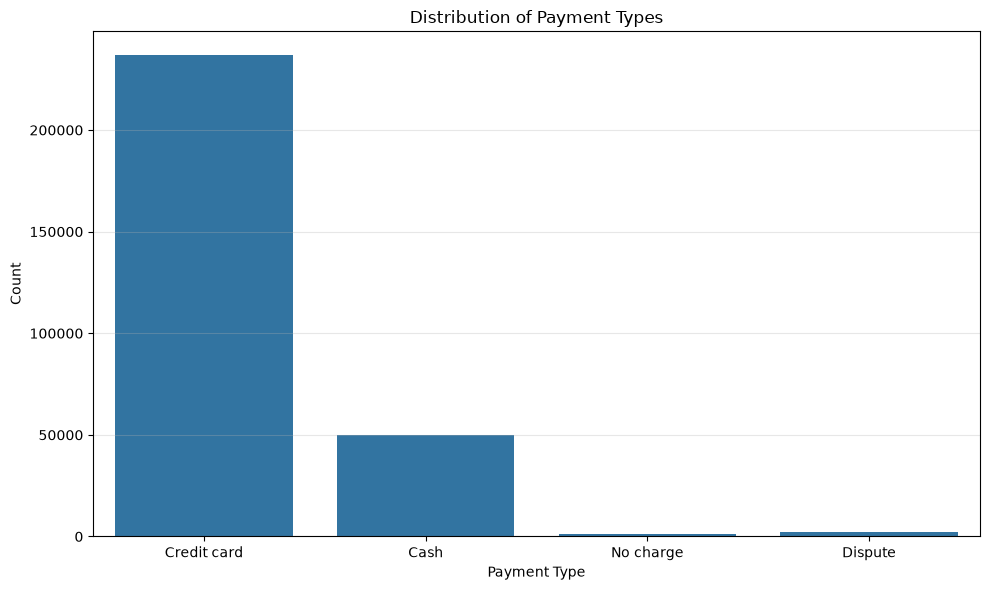

In [50]:
# Analyse the distribution of different payment types (payment_type).

# payment type labels as per data dictionary
payment_labels = {1: 'Credit card', 2: 'Cash', 3: 'No charge', 4: 'Dispute'}

# Create a bar plot
plt.figure(figsize=(10, 6))
ax = sns.countplot(data=df, x='payment_type', order=sorted(df['payment_type'].unique()))
ax.set_xticklabels([payment_labels.get(int(label.get_text()), label.get_text()) for label in ax.get_xticklabels()])
plt.xlabel('Payment Type')
plt.ylabel('Count')
plt.title('Distribution of Payment Types')
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()
# Most of the trip payments are made using Credit card

- 1= Credit card
- 2= Cash
- 3= No charge
- 4= Dispute



##### Geographical Analysis

For this, you have to use the *taxi_zones.shp* file from the *taxi_zones* folder.

There would be multiple files inside the folder (such as *.shx, .sbx, .sbn* etc). You do not need to import/read any of the files other than the shapefile, *taxi_zones.shp*.

Do not change any folder structure - all the files need to be present inside the folder for it to work.

The folder structure should look like this:
```
Taxi Zones
|- taxi_zones.shp.xml
|- taxi_zones.prj
|- taxi_zones.sbn
|- taxi_zones.shp
|- taxi_zones.dbf
|- taxi_zones.shx
|- taxi_zones.sbx

 ```

 You only need to read the `taxi_zones.shp` file. The *shp* file will utilise the other files by itself.

We will use the *GeoPandas* library for geopgraphical analysis
```
import geopandas as gpd
```

More about geopandas and shapefiles: [About](https://geopandas.org/en/stable/about.html)


Reading the shapefile is very similar to *Pandas*. Use `gpd.read_file()` function to load the data (*taxi_zones.shp*) as a GeoDataFrame. Documentation: [Reading and Writing Files](https://geopandas.org/en/stable/docs/user_guide/io.html)

In [51]:
!pip install geopandas

**3.1.9** <font color = red>[2 marks]</font> <br>
Load the shapefile and display it.

In [ ]:
import geopandas as gpd

shapefile_path = r'/content/drive/MyDrive/Colab Notebooks/taxi_zones/taxi_zones.shp'

# Read the shapefile using geopandas
zones = gpd.read_file(shapefile_path)
zones.head()


,OBJECTID,Shape_Leng,Shape_Area,zone,LocationID,borough,geometry
0,1,0.116357,0.000782,Newark Airport,1,EWR,"POLYGON ((933100.918 192536.086, 933091.011 19..."
1,2,0.433470,0.004866,Jamaica Bay,2,Queens,"MULTIPOLYGON (((1033269.244 172126.008, 103343..."
2,3,0.084341,0.000314,Allerton/Pelham Gardens,3,Bronx,"POLYGON ((1026308.77 256767.698, 1026495.593 2..."
3,4,0.043567,0.000112,Alphabet City,4,Manhattan,"POLYGON ((992073.467 203714.076, 992068.667 20..."
4,5,0.092146,0.000498,Arden Heights,5,Staten Island,"POLYGON ((935843.31 144283.336, 936046.565 144..."


Now, if you look at the DataFrame created, you will see columns like: `OBJECTID`,`Shape_Leng`, `Shape_Area`, `zone`, `LocationID`, `borough`, `geometry`.
<br><br>

Now, the `locationID` here is also what we are using to mark pickup and drop zones in the trip records.

The geometric parameters like shape length, shape area and geometry are used to plot the zones on a map.

This can be easily done using the `plot()` method.

<class 'geopandas.geodataframe.GeoDataFrame'>
RangeIndex: 263 entries, 0 to 262
Data columns (total 7 columns):
 #   Column      Non-Null Count  Dtype   
---  ------      --------------  -----   
 0   OBJECTID    263 non-null    int32   
 1   Shape_Leng  263 non-null    float64 
 2   Shape_Area  263 non-null    float64 
 3   zone        263 non-null    str     
 4   LocationID  263 non-null    int32   
 5   borough     263 non-null    str     
 6   geometry    263 non-null    geometry
dtypes: float64(2), geometry(1), int32(2), str(2)
memory usage: 18.5 KB
None


<Axes: xlabel='Easting [US survey foot]', ylabel='Northing [US survey foot]'>

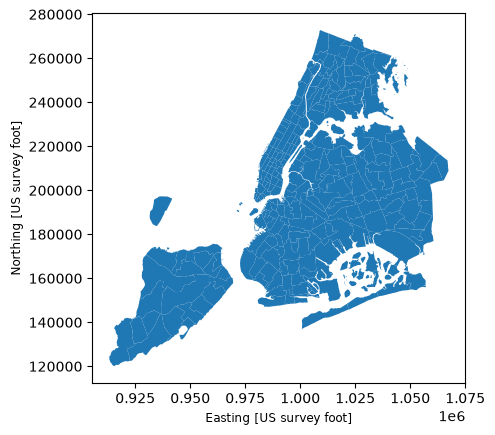

In [53]:
print(zones.info())
zones.plot()

Now, you have to merge the trip records and zones data using the location IDs.



**3.1.10** <font color = red>[3 marks]</font> <br>
Merge the zones data into trip data using the `locationID` and `PULocationID` columns.

In [54]:
# Merge zones and trip records using locationID and PULocationID
# Merge on PULocationID to get pickup zone information
df_with_zones = df.merge(zones,
                          left_on='PULocationID',
                          right_on='LocationID',
                          how='left')

# Drop the duplicate LocationID column from zones
df_with_zones = df_with_zones.drop('LocationID', axis=1)

print("Shape of merged data:", df_with_zones.shape)


Shape of merged data: (290199, 29)


**3.1.11** <font color = red>[3 marks]</font> <br>
Group data by location IDs to find the total number of trips per location ID

In [55]:
# Group data by location and calculate the number of trips
trips_per_location = df_with_zones.groupby('PULocationID').size().reset_index(name='trip_count')
# some sample rows of trips_per_location
trips_per_location.sort_values('trip_count', ascending=False).head(5)

,PULocationID,trip_count
114,132,15326
210,237,13769
142,161,13637
209,236,12153
143,162,10589


**3.1.12** <font color = red>[2 marks]</font> <br>
Now, use the grouped data to add number of trips to the GeoDataFrame.

We will use this to plot a map of zones showing total trips per zone.

In [56]:
# Merge trip counts back to the zones GeoDataFrame
zones_with_trips = zones.merge(trips_per_location,
                                left_on='LocationID',
                                right_on='PULocationID',
                                how='left')
# Fill NaN values with 0 (zones with no trips)
zones_with_trips['trip_count'] = zones_with_trips['trip_count'].fillna(0)
#droping the PULocationID column as it is duplicate of LocationID and not needed for further analysis
zones_with_trips = zones_with_trips.drop('PULocationID', axis=1)
zones_with_trips.head()


,OBJECTID,Shape_Leng,Shape_Area,zone,LocationID,borough,geometry,trip_count
0,1,0.116357,0.000782,Newark Airport,1,EWR,"POLYGON ((933100.918 192536.086, 933091.011 19...",35.0
1,2,0.433470,0.004866,Jamaica Bay,2,Queens,"MULTIPOLYGON (((1033269.244 172126.008, 103343...",0.0
2,3,0.084341,0.000314,Allerton/Pelham Gardens,3,Bronx,"POLYGON ((1026308.77 256767.698, 1026495.593 2...",5.0
3,4,0.043567,0.000112,Alphabet City,4,Manhattan,"POLYGON ((992073.467 203714.076, 992068.667 20...",299.0
4,5,0.092146,0.000498,Arden Heights,5,Staten Island,"POLYGON ((935843.31 144283.336, 936046.565 144...",6.0


The next step is creating a color map (choropleth map) showing zones by the number of trips taken.

Again, you can use the `zones.plot()` method for this. [Plot Method GPD](https://geopandas.org/en/stable/docs/reference/api/geopandas.GeoDataFrame.plot.html#geopandas.GeoDataFrame.plot)

But first, you need to define the figure and axis for the plot.

`fig, ax = plt.subplots(1, 1, figsize = (12, 10))`

This function creates a figure (fig) and a single subplot (ax)

---

After setting up the figure and axis, we can proceed to plot the GeoDataFrame on this axis. This is done in the next step where we use the plot method of the GeoDataFrame.

You can define the following parameters in the `zones.plot()` method:
```
column = '',
ax = ax,
legend = True,
legend_kwds = {'label': "label", 'orientation': "<horizontal/vertical>"}
```

To display the plot, use `plt.show()`.

**3.1.13** <font color = red>[3 marks]</font> <br>
Plot a color-coded map showing zone-wise trips

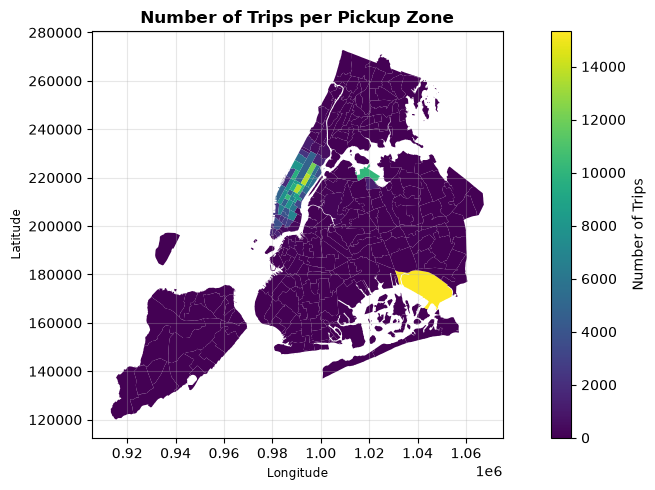

In [57]:
# Define figure and axis
fig, ax = plt.subplots(1, 1, figsize = (10, 5))

# Plot the map with color coding based on trip count
zones_with_trips.plot(
    column='trip_count',
    ax=ax,
    legend=True,
    legend_kwds={'label': 'Number of Trips', 'orientation': 'vertical'},

)

# Customize the plot
ax.set_title('Number of Trips per Pickup Zone', fontweight='bold')
ax.set_xlabel('Longitude')
ax.set_ylabel('Latitude')
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [58]:
# Display the zones DF sorted by the number of trips

zones_sorted = zones_with_trips.sort_values('trip_count',ascending=False)
zones_sorted.head(10)

,OBJECTID,Shape_Leng,Shape_Area,zone,LocationID,borough,geometry,trip_count
131,132,0.245479,0.002038,JFK Airport,132,Queens,"MULTIPOLYGON (((1032791.001 181085.006, 103283...",15326.0
236,237,0.042213,0.000096,Upper East Side South,237,Manhattan,"POLYGON ((993633.442 216961.016, 993507.232 21...",13769.0
160,161,0.035804,0.000072,Midtown Center,161,Manhattan,"POLYGON ((991081.026 214453.698, 990952.644 21...",13637.0
235,236,0.044252,0.000103,Upper East Side North,236,Manhattan,"POLYGON ((995940.048 221122.92, 995812.322 220...",12153.0
161,162,0.035270,0.000048,Midtown East,162,Manhattan,"POLYGON ((992224.354 214415.293, 992096.999 21...",10589.0
185,186,0.024696,0.000037,Penn Station/Madison Sq West,186,Manhattan,"POLYGON ((986752.603 210853.699, 986627.863 21...",10193.0
137,138,0.107467,0.000537,LaGuardia Airport,138,Queens,"MULTIPOLYGON (((1019904.219 225677.983, 102031...",10116.0
141,142,0.038176,0.000076,Lincoln Square East,142,Manhattan,"POLYGON ((989380.305 218980.247, 989359.803 21...",9678.0
229,230,0.031028,0.000056,Times Sq/Theatre District,230,Manhattan,"POLYGON ((988786.877 214532.094, 988650.277 21...",9656.0
169,170,0.045769,0.000074,Murray Hill,170,Manhattan,"POLYGON ((991999.299 210994.739, 991972.635 21...",8608.0


Here we have completed the temporal, financial and geographical analysis on the trip records.

**Compile your findings from general analysis below:**

You can consider the following points:

* Busiest hours, days and months
* Trends in revenue collected
* Trends in quarterly revenue
* How fare depends on trip distance, trip duration and passenger counts
* How tip amount depends on trip distance
* Busiest zones


### Summarizing the findings from analysis done from 3.1.1 to 3.1.13

**1. Taxi Service Usage patterns:**

   **Busiest Hours:**
   - Peak hour is **18:00 (6 PM) with 20,614 pickups**, representing the evening commute when people travel from offices to homes, and when people go out for dinner and entertainment.
   - Slowest hour is **5:00 AM with only 1,578 pickups** (early morning when most people are sleeping).
   - Average pickups per hour: **12,090.71 trips**, showing significant variation throughout the day with a clear peak during evening hours.

   **Busiest Days:**
   - Most active day is **Thursday with 45,546 pickups**, indicating that mid-week sees the highest demand for taxi services.
   - Least active day is **Sunday with 36,084 pickups**, showing that weekends have notably lower taxi usage.
   - Average pickups per day: **41,453.86 trips**, with weekdays (Tuesday-Thursday) showing significantly higher usage compared to weekends due to office commutes.

   **Busiest Months:**
   - Peak month is **May with 26,692 pickups**, driven by spring tourism and travel.
   - Slowest month is **September with 21,329 pickups**, possibly due to back-to-school and post-summer travel .
   - Average pickups per month: **24,181.42 trips**, showing consistent usage patterns with seasonal variations aligned with tourism and holiday periods.

**2. Revenue Collection Trends:**
   - **Highest revenue month:** May generates **$772,017.41** in total revenue.
   - **Lowest revenue month:** February generates **$593,590.30** in total revenue (winter season with lower activity).
   - **Average monthly revenue:** **$688,874.70**, showing that revenue directly correlates with trip volume.
   - Revenue collection demonstrates clear seasonal patterns, with higher revenue during months with increased taxi activity (spring and early summer).

**3. Quarterly Revenue Distribution:**
   - **Q1 (Jan-Mar):** $1,964,287.19 **(23.76%)** - Lowest performing quarter.
   - **Q2 (Apr-Jun):** $2,199,585.93 **(26.61%)** - Strong quarter driven by spring tourism and early summer travel.
   - **Q3 (Jul-Sep):** $1,883,526.18 **(22.79%)** - Lower revenue during summer vacation period.
   - **Q4 (Oct-Dec):** $2,219,097.10 **(26.84%)** - Highest revenue quarter due to holiday season, year-end celebrations, and winter tourism.

**4. Taxi Fare Dependency Analysis:**
   - **Fare Amount vs Trip Distance:** There is a **strong positive correlation** between trip distance and fare amount. Longer trips consistently result in higher fares, which is the primary driver of fare pricing.
   - **Fare Amount vs Trip Duration:** There is a **weak positive correlation (0.27)** between trip duration and fare amount. While there is a tendency for fares to increase with longer trips, this relationship is modest.
   - **Fare Amount vs Passenger Count:** There is **virtually no correlation (0.04)** between passenger count and fare amount. Passenger count has almost no impact on the fare amount charged, as fares are calculated based on distance and time, not the number of people in the vehicle.

**5. Tip Amount Dependency:**
   - **Tip Amount vs Trip Distance:** There is a **strong positive correlation (0.59)** between trip distance and tip amount, indicating that longer trips get more tips. Passengers appear to base tips on the perceived value and length of service.
   - **Pattern:** While the strong correlation shows distance is a major factor in tipping decisions, shorter trips also result in higher tips in some instances. This suggests that time of day, driver quality, payment method, and overall passenger satisfaction also significantly influence tipping behavior.

**6. Busiest Zones:**
   - **Top Pickup Location:** JFK Airport is the busiest pickup zone with the highest volume of taxi pickups, making it the primary hub for airport-related transportation.

**7. Payment Method Distribution:**
   - **Credit Card Dominance:** The majority of taxi trips are paid using credit cards, demonstrating the strong trend toward digital payments and cashless transactions in the NYC taxi service.
   - Cash payments represent a smaller but still significant portion of total transactions.
   - Other payment types ("No charge" and "Dispute") represent very small percentages of total transactions.

#### **3.2** Detailed EDA: Insights and Strategies
<font color = red>[50 marks]</font> <br>

Having performed basic analyses for finding trends and patterns, we will now move on to some detailed analysis focussed on operational efficiency, pricing strategies, and customer experience.

##### Operational Efficiency

Analyze variations by time of day and location to identify bottlenecks or inefficiencies in routes

**3.2.1** <font color = red>[3 marks]</font> <br>
Identify slow routes by calculating the average time taken by cabs to get from one zone to another at different hours of the day.

Speed on a route *X* for hour *Y* = (*distance of the route X / average trip duration for hour Y*)

In [59]:
# Find routes which have the slowest speeds at different times of the day


# Convert datetime columns to proper datetime type
df_with_zones['tpep_dropoff_datetime'] = pd.to_datetime(df_with_zones['tpep_dropoff_datetime'])
df_with_zones['tpep_pickup_datetime'] = pd.to_datetime(df_with_zones['tpep_pickup_datetime'])

#Take a copy to filter out invalid routes and calculate speed
df_valid_routes = df_with_zones.copy()

# Calculate trip duration in minutes
df_valid_routes['trip_duration_minutes'] = (df_valid_routes['tpep_dropoff_datetime'] - df_valid_routes['tpep_pickup_datetime']).dt.total_seconds() / 60
# Filter out trips with zero or negative duration and distance to avoid division by zero and invalid speeds
df_valid_routes=df_valid_routes[(df_valid_routes['trip_duration_minutes'] > 0) & (df_valid_routes['trip_distance'] > 0)]

df_valid_routes['trip_duration_hours'] = df_valid_routes['trip_duration_minutes'] / 60
df_valid_routes['speed_mph'] = df_valid_routes['trip_distance'] / df_valid_routes['trip_duration_hours']

# 2. Extract hour from pickup time and create route identifier
df_valid_routes['pickup_hour'] = df_valid_routes['tpep_pickup_datetime'].dt.hour
#store route as a string in the format "PULocationID → DOLocationID"
df_valid_routes['route'] = df_valid_routes['PULocationID'].astype(str) + ' → ' + df_valid_routes['DOLocationID'].astype(str)

# Calculate average speed by route and hour
route_speed = df_valid_routes.groupby(['route', 'pickup_hour']).agg(
    avg_speed=('speed_mph', 'mean'),
    avg_distance=('trip_distance', 'mean'),
    avg_duration=('trip_duration_minutes', 'mean')
).reset_index()

# Statistics Summary
slowest_by_hour = route_speed.loc[route_speed.groupby('pickup_hour')['avg_speed'].idxmin()]
slowest_by_hour = slowest_by_hour.sort_values('pickup_hour')
#Routes with the slowest average speeds for each hour of the day, along with their average distance and duration, are displayed below.
print(slowest_by_hour)


           route  pickup_hour  avg_speed  avg_distance  avg_duration
9722    132 → 74            0   0.776789         18.02   1391.883333
53117   48 → 132            1   0.058116          1.07   1104.683333
11424  138 → 129            2   1.855670          0.30      9.700000
3363   113 → 246            3   0.053374          1.28   1438.900000
18301  144 → 186            4   0.088237          2.08   1414.366667
51180   40 → 106            5   3.577236          1.10     18.450000
41      10 → 218            6   0.448319          0.20     26.766667
5        10 → 10            7   0.155172          0.01      3.866667
32655   211 → 48            8   1.212121          0.50     24.750000
19060  146 → 226            9   0.093926          1.40    894.316667
51633    42 → 42           10   0.419825          0.20     28.583333
44752  244 → 177           11   0.234872          0.40    102.183333
31495  207 → 207           12   0.404494          0.01      1.483333
34330   229 → 41           13   0.

How does identifying high-traffic, high-demand routes help us?


1. **Revenue Optimization**: High-demand routes allow dynamic pricing strategies and better resource allocation to maximize profitability and driver earnings during peak hours.

2. **Operational Efficiency**: Predict dispatch, and smart scheduling so vehicles are available where and when customers need them most.

3. **Customer Experience**: Reduces wait times, ensures service reliability, and provides accurate ETAs on popular routes, leading to higher satisfaction and customer retention.

4. **Infrastructure Planning**: Provides data-driven insights for infrastructure investments

**3.2.2** <font color = red>[3 marks]</font> <br>
Calculate the number of trips at each hour of the day and visualise them. Find the busiest hour and show the number of trips for that hour.

pickup_hour
0      8068
1      5431
2      3485
3      2360
4      1600
5      1578
6      3878
7      7814
8     10773
9     12257
10    13543
11    14493
12    15892
13    16284
14    17679
15    18234
16    18023
17    19432
18    20615
19    18466
20    16669
21    16485
22    15218
23    11922
Name: count, dtype: int64
Busiest Hour: 18:00 with 20615 trips


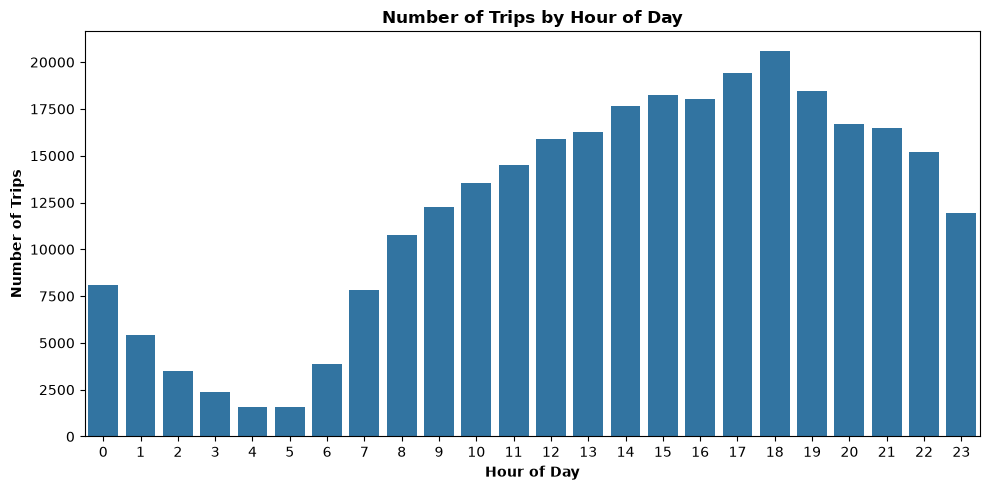

In [60]:
# Visualise the number of trips per hour and find the busiest hour

# Count trips per hour using df_with_zones
trips_per_hour = df_with_zones['pickup_hour'].value_counts().sort_index()
print(trips_per_hour)
# Find the busiest hour
busiest_hour = trips_per_hour.idxmax()
busiest_hour_trips = trips_per_hour.max()
print(f'Busiest Hour: {busiest_hour}:00 with {busiest_hour_trips} trips')

# Create visualization
plt.figure(figsize=(10, 5))
sns.barplot(x=trips_per_hour.index, y=trips_per_hour.values)

plt.xlabel('Hour of Day',  fontweight='bold')
plt.ylabel('Number of Trips', fontweight='bold')
plt.title('Number of Trips by Hour of Day', fontweight='bold')
plt.xticks(range(24))
plt.tight_layout()
plt.show()


Remember, we took a fraction of trips. To find the actual number, you have to scale the number up by the sampling ratio.

**3.2.3** <font color = red>[2 mark]</font> <br>
Find the actual number of trips in the five busiest hours

In [61]:
# Scale up the number of trips

# Fill in the value of your sampling fraction and use that to scale up the numbers
sample_fraction = 0.05

# Five busiest sampled hours
busiest_hour_5 = (trips_per_hour.sort_values(ascending=False) .head(5))

# Scaled to find the trips to match actual number of trips
actual_busiest_hour_5 = (busiest_hour_5 / sample_fraction)

print("Top 5 busiest hours from the sampled records:")
print(busiest_hour_5)

print('Top 5 busiest hours that could be present in actual trips:')
print(actual_busiest_hour_5.round().astype(int))

Top 5 busiest hours from the sampled records:
pickup_hour
18    20615
17    19432
19    18466
15    18234
16    18023
Name: count, dtype: int64
Top 5 busiest hours that could be present in actual trips:
pickup_hour
18    412300
17    388640
19    369320
15    364680
16    360460
Name: count, dtype: int64


**3.2.4** <font color = red>[3 marks]</font> <br>
Compare hourly traffic pattern on weekdays. Also compare for weekend.

In [62]:
df_with_zones['pickup_day_of_week'].unique()

array([3, 4, 6, 2, 0, 5, 1], dtype=int32)

Hourly trips comparison - Weekday vs Weekend:
day_type     Weekday  Weekend
pickup_hour                  
0               4087     3981
1               2046     3385
2               1077     2408
3                686     1674
4                695      905
5               1193      385
6               3293      585
7               6818      996
8               9179     1594
9               9876     2381
10             10175     3368
11             10624     3869
12             11561     4331
13             11763     4521
14             13036     4643
15             13502     4732
16             13136     4887
17             14527     4905
18             15695     4920
19             13767     4699
20             12589     4080
21             12605     3880
22             11451     3767
23              8499     3423


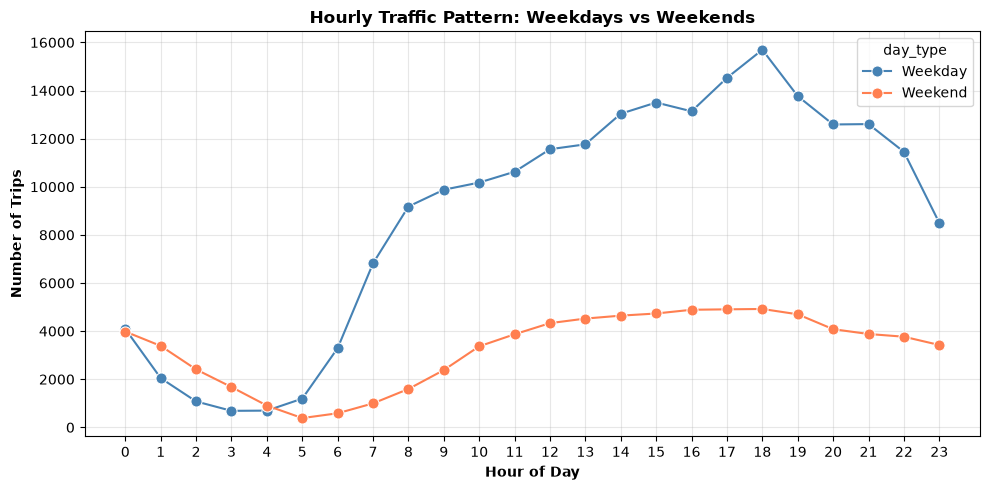

Peak Hours Comparison
----------------------------------------------------------------------
Weekday: Busiest hour is 18:00 with 15,695 trips
Weekend: Busiest hour is 18:00 with 4,920 trips


In [63]:
# Compare traffic trends for the week days and weekends


# Create weekday/weekend label
df_with_zones['day_type'] = df_with_zones['pickup_day_of_week'].apply(
    lambda x: 'Weekday' if x < 5 else 'Weekend'
)
# Count trips by hour and day type
hourly_trip_by_day_type = df_with_zones.groupby(['pickup_hour', 'day_type']).size().unstack(fill_value=0)
print("Hourly trips comparison - Weekday vs Weekend:")
print(hourly_trip_by_day_type)

# Visualize comparison
plt.figure(figsize=(10,5))
# Prepare data for seaborn line plot
hourly_day_type_data = df_with_zones.groupby(['pickup_hour', 'day_type']).size().reset_index(name='trips')

sns.lineplot(data=hourly_day_type_data, x='pickup_hour', y='trips', hue='day_type',
             marker='o',  markersize=8, palette=['steelblue', 'coral'])

plt.xlabel('Hour of Day', fontweight='bold')
plt.ylabel('Number of Trips', fontweight='bold')
plt.title('Hourly Traffic Pattern: Weekdays vs Weekends', fontweight='bold')
plt.xticks(range(0, 24))
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# Find busiest hours for each day type
print("Peak Hours Comparison")
print("-"*70)
for day_type in ['Weekday', 'Weekend']:
    busiest = hourly_trip_by_day_type[day_type].idxmax()
    trips = hourly_trip_by_day_type[day_type].max()
    print(f"{day_type}: Busiest hour is {busiest}:00 with {trips:,} trips")

What can you infer from the above patterns? How will finding busy and quiet hours for each day help us?



**Ans** : Knowing busy and quiet hours for each day type allows better fleet allocation and driver scheduling, deploying more cabs during weekday rush hours and weekend nights while reducing idle fleet during quiet hours. It also supports dynamic pricing during peak-demand windows and lets maintenance/driver breaks be scheduled during low-demand periods, improving both efficiency and service availability.



**3.2.5** <font color = red>[3 marks]</font> <br>
Identify top 10 zones with high hourly pickups. Do the same for hourly dropoffs. Show pickup and dropoff trends in these zones.

Top 10 Pickup Zones:
     PULocationID                          zone  pickup_count
113           132                   JFK Airport         15326
209           237         Upper East Side South         13769
141           161                Midtown Center         13637
208           236         Upper East Side North         12153
142           162                  Midtown East         10589
163           186  Penn Station/Madison Sq West         10193
119           138             LaGuardia Airport         10116
123           142           Lincoln Square East          9678
202           230     Times Sq/Theatre District          9656
150           170                   Murray Hill          8608

Top 10 Dropoff Zones:
     DOLocationID                       zone  dropoff_count
229           236      Upper East Side North          12734
230           237      Upper East Side South          12150
156           161             Midtown Center          11325
223           230  Times Sq/Theatr

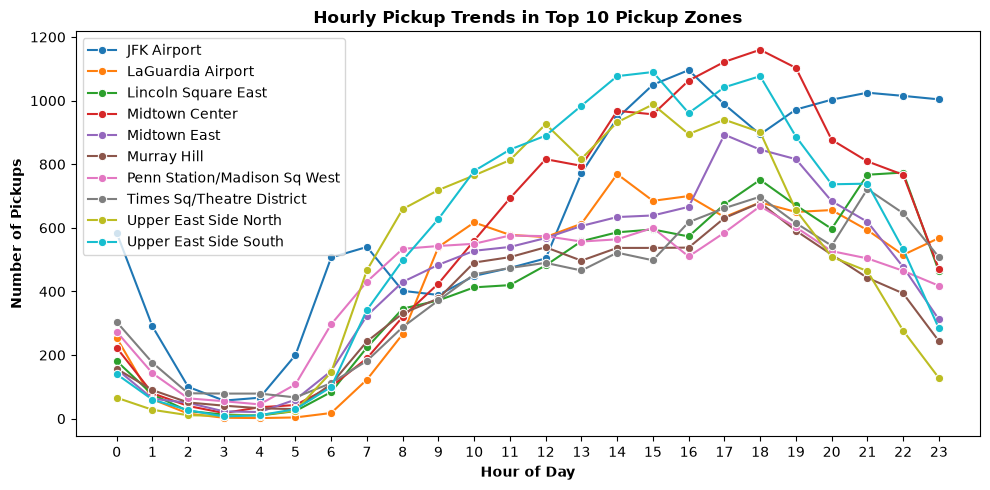

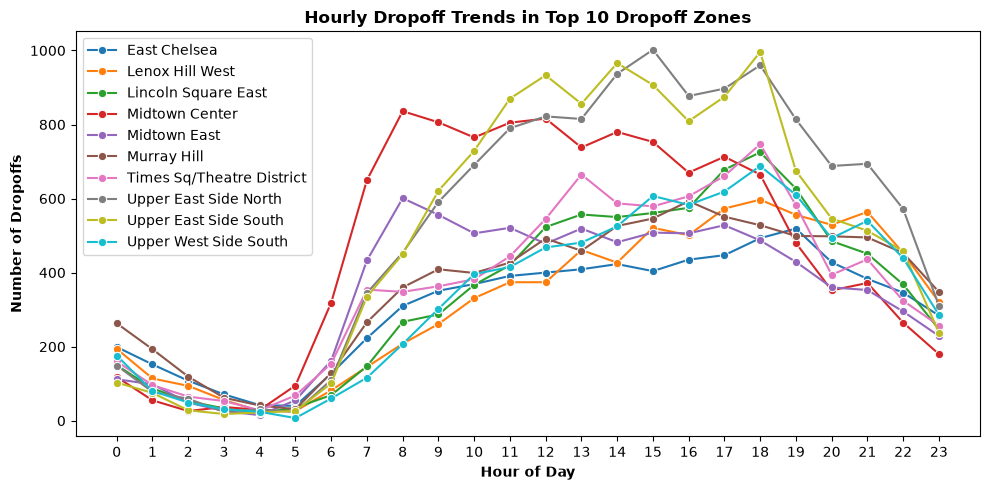

In [64]:
# Find top 10 pickup and dropoff zones

# Top 10 pickup zones (using zone names already merged in df_with_zones via PULocationID)
top_10_pickup_zones = (df_with_zones.groupby(['PULocationID', 'zone'])
                        .size()
                        .reset_index(name='pickup_count')
                        .sort_values('pickup_count', ascending=False)
                        .head(10))
print("Top 10 Pickup Zones:")
print(top_10_pickup_zones)

# Top 10 dropoff zones (merge zones on DOLocationID to get dropoff zone names)
dropoff_counts = df_with_zones.groupby('DOLocationID').size().reset_index(name='dropoff_count')
dropoff_counts = dropoff_counts.merge(zones[['LocationID', 'zone']],
                                       left_on='DOLocationID', right_on='LocationID',
                                       how='left')
top_10_dropoff_zones = dropoff_counts.sort_values('dropoff_count', ascending=False).head(10)
print("\nTop 10 Dropoff Zones:")
print(top_10_dropoff_zones[['DOLocationID', 'zone', 'dropoff_count']])

# Hourly pickup trend for top 10 pickup zones
top_pickup_zone_ids = top_10_pickup_zones['PULocationID'].tolist()
hourly_pickup_trend = (df_with_zones[df_with_zones['PULocationID'].isin(top_pickup_zone_ids)]
                        .groupby(['pickup_hour', 'zone'])
                        .size()
                        .reset_index(name='trips'))

plt.figure(figsize=(10, 5))
sns.lineplot(data=hourly_pickup_trend, x='pickup_hour', y='trips', hue='zone', marker='o')
plt.xlabel('Hour of Day', fontweight='bold')
plt.ylabel('Number of Pickups', fontweight='bold')
plt.title('Hourly Pickup Trends in Top 10 Pickup Zones', fontweight='bold')
plt.xticks(range(0, 24))
plt.legend(loc='upper left')
plt.tight_layout()
plt.show()

# Hourly dropoff trend for top 10 dropoff zones
top_dropoff_zone_ids = top_10_dropoff_zones['DOLocationID'].tolist()
df_with_zones_dropoff = df_with_zones.merge(zones[['LocationID', 'zone']],
                                             left_on='DOLocationID', right_on='LocationID',
                                             how='left', suffixes=('', '_dropoff'))
hourly_dropoff_trend = (df_with_zones_dropoff[df_with_zones_dropoff['DOLocationID'].isin(top_dropoff_zone_ids)]
                         .groupby(['pickup_hour', 'zone_dropoff'])
                         .size()
                         .reset_index(name='trips'))

plt.figure(figsize=(10, 5))
sns.lineplot(data=hourly_dropoff_trend, x='pickup_hour', y='trips', hue='zone_dropoff', marker='o')
plt.xlabel('Hour of Day', fontweight='bold')
plt.ylabel('Number of Dropoffs', fontweight='bold')
plt.title('Hourly Dropoff Trends in Top 10 Dropoff Zones', fontweight='bold')
plt.xticks(range(0, 24))
plt.legend(loc='upper left')
plt.tight_layout()
plt.show()

**3.2.6** <font color = red>[3 marks]</font> <br>
Find the ratio of pickups and dropoffs in each zone. Display the 10 highest (pickup/drop) and 10 lowest (pickup/drop) ratios.

In [65]:
# Find the top 10 and bottom 10 pickup/dropoff ratios

# Each LocationID maps to a zone name, so we aggregate by zone name (multiple location IDs can share a zone name)
# Step 1: Calculate zone-wise pickup count (using the pickup 'zone' name already merged into df_with_zones via PULocationID)
zone_pickup_count = df_with_zones.groupby('zone').size().reset_index(name='pickup_count')

# Calculate zone-wise dropoff count
# First attach the dropoff zone name by mapping DOLocationID to the zones lookup table
zone_lookup = zones.drop_duplicates(subset='LocationID').set_index('LocationID')['zone']
dropoff_zone_name = df_with_zones['DOLocationID'].map(zone_lookup)
zone_dropoff_count = dropoff_zone_name.value_counts().rename_axis('zone').reset_index(name='dropoff_count')

# Merge the pickup and dropoff counts into a single DataFrame, one row per zone
zone_ratio = zone_pickup_count.merge(zone_dropoff_count, on='zone', how='outer')
zone_ratio['pickup_count'] = zone_ratio['pickup_count'].fillna(0)
zone_ratio['dropoff_count'] = zone_ratio['dropoff_count'].fillna(0)

# Calculate the pickup/dropoff ratio for each zone
zone_ratio['pickup_dropoff_ratio'] = zone_ratio['pickup_count'] / zone_ratio['dropoff_count'].replace(0, np.nan)

# Sort by ratio and display top 10 and bottom 10
zone_ratio = zone_ratio.sort_values('pickup_dropoff_ratio', ascending=False)

print('Top 10 Zones with Highest Pickup/Dropoff Ratio:')
print(zone_ratio.head(10))

print('Top 10 Zones with Lowest Pickup/Dropoff Ratio:')
print(zone_ratio.tail(10))

Top 10 Zones with Highest Pickup/Dropoff Ratio:
                             zone  pickup_count  dropoff_count  \
66                  East Elmhurst        1283.0            159   
120                   JFK Airport       15326.0           3477   
2                   Arden Heights           6.0              2   
130             LaGuardia Airport       10116.0           3497   
179  Penn Station/Madison Sq West       10193.0           6473   
41         Charleston/Tottenville           3.0              2   
105       Greenwich Village South        3908.0           2778   
40                   Central Park        4836.0           3495   
240                  West Village        6508.0           4837   
154                  Midtown East       10589.0           8308   

     pickup_dropoff_ratio  
66               8.069182  
120              4.407823  
2                3.000000  
130              2.892765  
179              1.574695  
41               1.500000  
105              1.406767  
4

**3.2.7** <font color = red>[3 marks]</font> <br>
Identify zones with high pickup and dropoff traffic during night hours (11PM to 5AM)

In [66]:
# During night hours (11pm to 5am) find the top 10 pickup and dropoff zones
# Note that the top zones should be of night hours and not the overall top zones

# Filter trips occurring during night hours (23:00 to 04:59)
night_trips = df_with_zones[(df_with_zones['pickup_hour'] >= 23) | (df_with_zones['pickup_hour'] <= 4)]

# Top 10 pickup zones during night hours
night_pickup_count = night_trips.groupby('zone').size().reset_index(name='pickup_count')
top_10_night_pickup_zones = night_pickup_count.sort_values('pickup_count', ascending=False).head(10)
print("Top 10 Pickup Zones (Night Hours 11PM-5AM):")
print(top_10_night_pickup_zones)

# Top 10 dropoff zones during night hours (map DOLocationID to zone name using deduped lookup)
zone_lookup = zones.drop_duplicates(subset='LocationID').set_index('LocationID')['zone']
night_dropoff_zone_name = night_trips['DOLocationID'].map(zone_lookup)
night_dropoff_count = night_dropoff_zone_name.value_counts().rename_axis('zone').reset_index(name='dropoff_count')
top_10_night_dropoff_zones = night_dropoff_count.sort_values('dropoff_count', ascending=False).head(10)
print("\nTop 10 Dropoff Zones (Night Hours 11PM-5AM):")
print(top_10_night_dropoff_zones)

Top 10 Pickup Zones (Night Hours 11PM-5AM):
                             zone  pickup_count
44                   East Village          2442
70                    JFK Airport          2101
149                  West Village          2020
27                   Clinton East          1542
88                Lower East Side          1507
64        Greenwich Village South          1403
133     Times Sq/Theatre District          1226
106  Penn Station/Madison Sq West           998
36                   East Chelsea           988
97                  Midtown South           988

Top 10 Dropoff Zones (Night Hours 11PM-5AM):
                            zone  dropoff_count
0                   East Village           1372
1                   Clinton East           1030
2                    Murray Hill           1026
3                       Gramercy            907
4                   East Chelsea            856
5                 Yorkville West            841
6                Lenox Hill West            80

Now, let us find the revenue share for the night time hours and the day time hours. After this, we will move to deciding a pricing strategy.

**3.2.8** <font color = red>[2 marks]</font> <br>
Find the revenue share for nighttime and daytime hours.

In [67]:
# Filter for night hours (11 PM to 5 AM)
night_trips = df_with_zones[(df_with_zones['pickup_hour'] >= 23) | (df_with_zones['pickup_hour'] <= 4)]
# Calculate revenue for night hours
night_revenue = night_trips['total_amount'].sum()
# Filter for day hours (5 AM to 11 PM)
day_trips = df_with_zones[(df_with_zones['pickup_hour'] >= 5) & (df_with_zones['pickup_hour'] < 23)]
# Calculate revenue for day hours
day_revenue = day_trips['total_amount'].sum()
# Calculate total revenue
total_revenue = night_revenue + day_revenue
# Calculate revenue share (percentage)
night_revenue_share = (night_revenue / total_revenue) * 100
day_revenue_share = (day_revenue / total_revenue) * 100
print(f'Night Hours (11 PM - 5 AM) Revenue: ${round(night_revenue, 2)}')
print(f'Day Hours (5 AM - 11 PM) Revenue: ${round(day_revenue, 2)}')
print(f'Total Revenue: ${round(total_revenue, 2)}')
print(f'Night Revenue Share: {round(night_revenue_share, 2)}%')
print(f'Day Revenue Share: {round(day_revenue_share, 2)}%')

Night Hours (11 PM - 5 AM) Revenue: $953708.35
Day Hours (5 AM - 11 PM) Revenue: $7434940.07
Total Revenue: $8388648.42
Night Revenue Share: 11.37%
Day Revenue Share: 88.63%


##### Pricing Strategy

**3.2.9** <font color = red>[2 marks]</font> <br>
For the different passenger counts, find the average fare per mile per passenger.

For instance, suppose the average fare per mile for trips with 3 passengers is 3 USD/mile, then the fare per mile per passenger will be 1 USD/mile.

Average Fare Per Mile Per Passenger by Passenger Count:
   passenger_count  avg_fare_per_mile_per_passenger
0              1.0                        10.906006
1              2.0                         6.009718
2              3.0                         3.765414
3              4.0                         4.104135
4              5.0                         1.859741
5              6.0                         1.585483


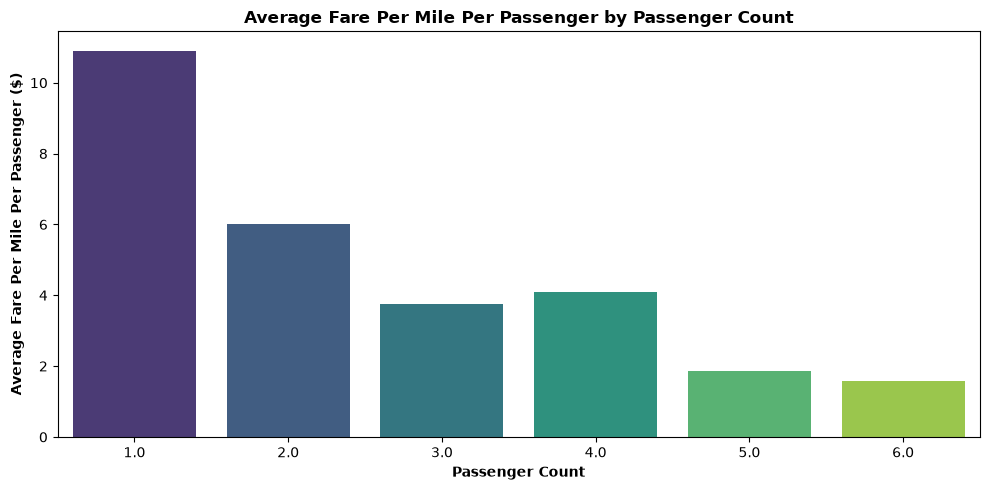

In [68]:
# Analyse the fare per mile per passenger for different passenger counts

# Filter out zero trip distances to avoid infinity errors
df_fare = df_with_zones[df_with_zones['trip_distance'] > 0].copy()

# Calculate fare per mile and then fare per mile per passenger
df_fare['fare_per_mile'] = df_fare['fare_amount'] / df_fare['trip_distance']
df_fare['fare_per_mile_per_passenger'] = df_fare['fare_per_mile'] / df_fare['passenger_count']

# Group by passenger count and calculate average fare per mile per passenger
avg_fare_by_passenger = df_fare.groupby('passenger_count')['fare_per_mile_per_passenger'].mean().reset_index(name='avg_fare_per_mile_per_passenger')
avg_fare_by_passenger = avg_fare_by_passenger.sort_values('passenger_count')

print("Average Fare Per Mile Per Passenger by Passenger Count:")
print(avg_fare_by_passenger)

#Visualize the average fare per mile per passenger by passenger count
plt.figure(figsize=(10, 5))
sns.barplot(data=avg_fare_by_passenger, x='passenger_count', y='avg_fare_per_mile_per_passenger', palette='viridis')
plt.xlabel('Passenger Count', fontweight='bold')
plt.ylabel('Average Fare Per Mile Per Passenger ($)', fontweight='bold')
plt.title('Average Fare Per Mile Per Passenger by Passenger Count', fontweight='bold')
plt.tight_layout()
plt.show()

**3.2.10** <font color = red>[3 marks]</font> <br>
Find the average fare per mile by hours of the day and by days of the week

Average Fare Per Mile by Hour of Day:
    tpep_pickup_datetime  avg_fare_per_mile
0                      0           7.713211
1                      1           8.802000
2                      2          14.348523
3                      3           8.633007
4                      4          15.257833
5                      5          14.142011
6                      6           6.697633
7                      7           9.033557
8                      8           9.492908
9                      9          11.046197
10                    10          10.775173
11                    11          12.350917
12                    12          12.351269
13                    13          12.950094
14                    14          11.123514
15                    15          14.389170
16                    16          14.366949
17                    17          10.815494
18                    18          11.575128
19                    19          10.950075
20                    20           9.1

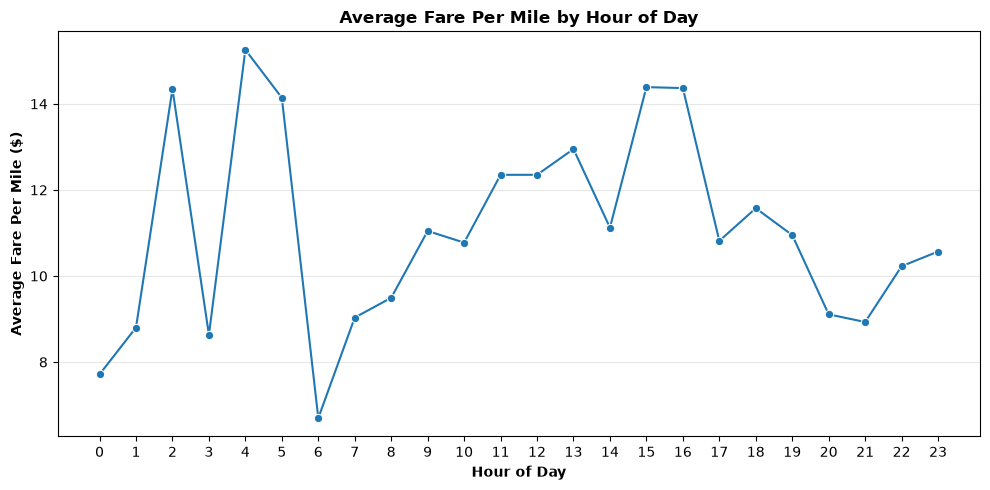

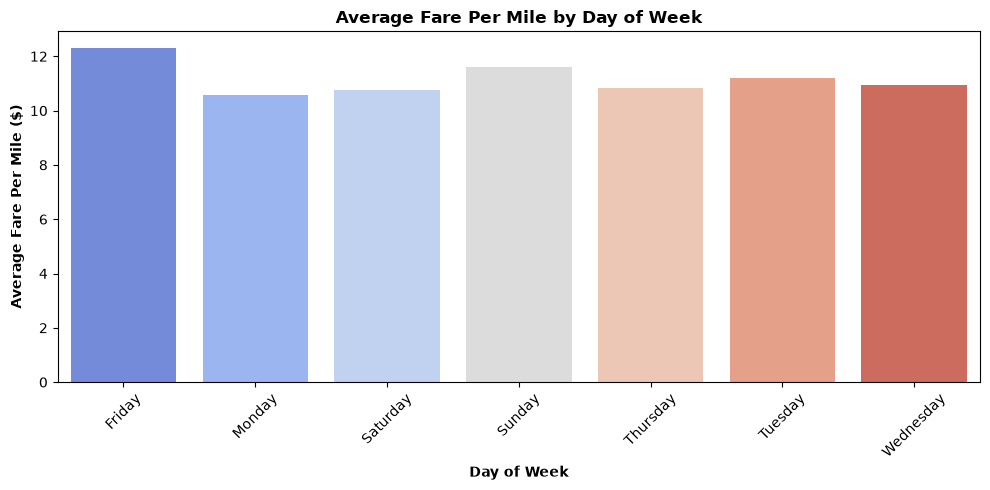

In [69]:
# Compare the average fare per mile for different days and for different times of the day

# Filter out zero trip distances to avoid infinity errors
df_fare = df_with_zones[df_with_zones['trip_distance'] > 0].copy()

# Calculate fare per mile
df_fare['fare_per_mile'] = df_fare['fare_amount'] / df_fare['trip_distance']

# Extract day of week from pickup datetime
df_fare['pickup_day_of_week'] = df_fare['tpep_pickup_datetime'].dt.day_name()

# Calculate average fare per mile by hour of day
fare_by_hour = df_fare.groupby(df_fare['tpep_pickup_datetime'].dt.hour)['fare_per_mile'].mean().reset_index(name='avg_fare_per_mile')
print(f'Average Fare Per Mile by Hour of Day:')
print(fare_by_hour)

# Calculate average fare per mile by day of week
fare_by_day = df_fare.groupby('pickup_day_of_week')['fare_per_mile'].mean().reset_index(name='avg_fare_per_mile')
fare_by_day = fare_by_day.sort_values('pickup_day_of_week')
print(f'Average Fare Per Mile by Day of Week:')
print(fare_by_day)

#visualize the average fare per mile by hour of day
plt.figure(figsize=(10, 5))
sns.lineplot(data=fare_by_hour, x='tpep_pickup_datetime', y='avg_fare_per_mile', marker='o')
plt.xlabel('Hour of Day', fontweight='bold')
plt.xticks(ticks=range(0, 24), labels=range(0, 24))
plt.xlabel('Hour of Day', fontweight='bold')
plt.ylabel('Average Fare Per Mile ($)', fontweight='bold')
plt.title('Average Fare Per Mile by Hour of Day', fontweight='bold')
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

#visualize the average fare per mile by day of week
plt.figure(figsize=(10, 5))
sns.barplot(data=fare_by_day, x='pickup_day_of_week', y='avg_fare_per_mile', palette='coolwarm')
plt.xlabel('Day of Week', fontweight='bold')
plt.ylabel('Average Fare Per Mile ($)', fontweight='bold')
plt.title('Average Fare Per Mile by Day of Week', fontweight='bold')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


**3.2.11** <font color = red>[3 marks]</font> <br>
Analyse the average fare per mile for the different vendors for different hours of the day

Average Fare Per Mile by Vendor and Hour of Day:
    VendorID  pickup_hour  avg_fare_per_mile
0          1            0           6.738486
1          1            1           6.542841
2          1            2           6.684378
3          1            3           8.754964
4          1            4           8.997251
5          1            5           7.130077
6          1            6           6.645695
7          1            7           6.964569
8          1            8           8.106641
9          1            9           8.915459
10         1           10           8.295374
11         1           11           8.762510
12         1           12           9.060286
13         1           13           8.846128
14         1           14           8.753626
15         1           15           8.647871
16         1           16           8.654743
17         1           17           8.544525
18         1           18           8.326781
19         1           19           8.040118
20    

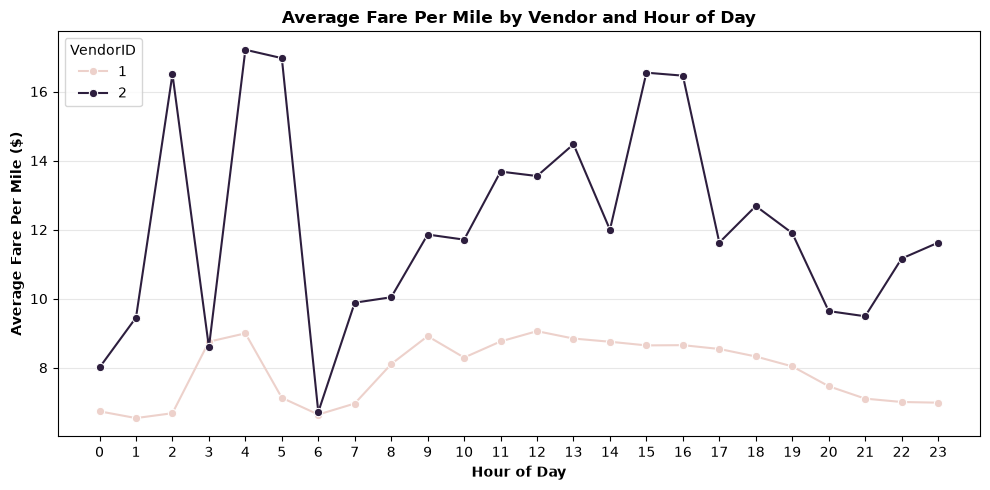

In [70]:
# Compare fare per mile for different vendors

# Filter out zero trip distances to avoid infinity
df_fare = df_with_zones[df_with_zones['trip_distance'] > 0].copy()

# Calculate fare per mile
df_fare['fare_per_mile'] = df_fare['fare_amount'] / df_fare['trip_distance']

# Group by vendor and hour, calculate average fare per mile
fare_by_vendor_hour = df_fare.groupby(['VendorID', 'pickup_hour'])['fare_per_mile'].mean().reset_index(name='avg_fare_per_mile')
print("Average Fare Per Mile by Vendor and Hour of Day:")
print(fare_by_vendor_hour)

#visualize the average fare per mile by vendor and hour of day
plt.figure(figsize=(10, 5))
sns.lineplot(data=fare_by_vendor_hour, x='pickup_hour', y='avg_fare_per_mile', hue='VendorID', marker='o')
plt.xlabel('Hour of Day', fontweight='bold')
plt.ylabel('Average Fare Per Mile ($)', fontweight='bold')
plt.title('Average Fare Per Mile by Vendor and Hour of Day', fontweight='bold')
plt.xticks(range(0, 24))
plt.grid(axis='y', alpha=0.3)
plt.legend(title='VendorID', loc='upper left')
plt.tight_layout()
plt.show()

**3.2.12** <font color = red>[5 marks]</font> <br>
Compare the fare rates of the different vendors in a tiered fashion. Analyse the average fare per mile for distances upto 2 miles. Analyse the fare per mile for distances from 2 to 5 miles. And then for distances more than 5 miles.


Average Fare Per Mile by Vendor and Distance Tier:
   VendorID distance_tier  avg_fare_per_mile  trip_count
0         1     0-2 miles           9.936071       43079
1         1     2-5 miles           6.387448       19153
2         1      5+ miles           4.411282       11869
3         2     0-2 miles          17.571671      116685
4         2     2-5 miles           6.556506       58284
5         2      5+ miles           4.506595       37807


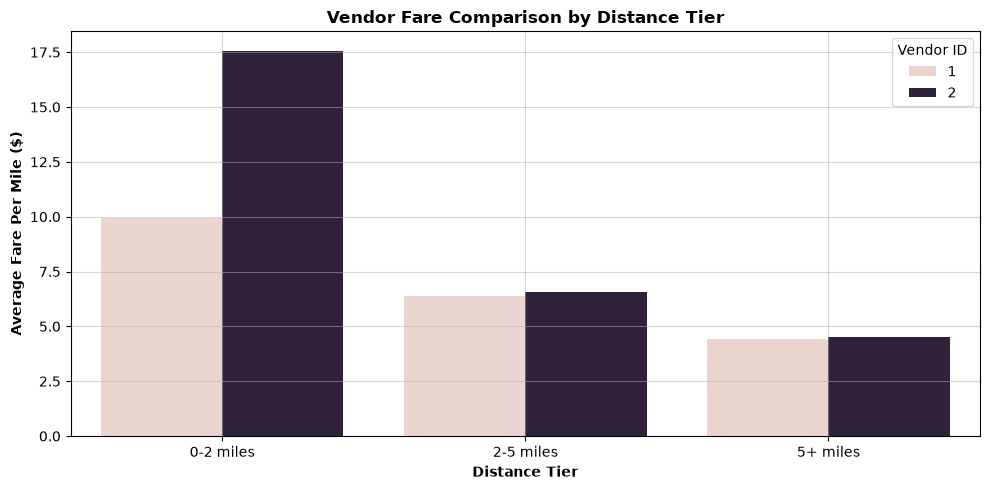

In [80]:
# Defining distance tiers and comparing vendor fare rates

# Filter data with non-zero distances
df_tier = df_with_zones[df_with_zones['trip_distance'] > 0].copy()

# Calculate fare per mile
df_tier['fare_per_mile'] = df_tier['fare_amount'] / df_tier['trip_distance']

# Create distance tiers
df_tier['distance_tier'] = pd.cut(df_tier['trip_distance'],
                                   bins=[0, 2, 5, float('inf')],
                                   labels=['0-2 miles', '2-5 miles', '5+ miles'])

# Analyze fare per mile by vendor and distance tier
vendor_tier_trip = df_tier.groupby(['VendorID', 'distance_tier'])['fare_per_mile'].agg(avg_fare_per_mile='mean', trip_count='count').reset_index()

print("Average Fare Per Mile by Vendor and Distance Tier:")
print(vendor_tier_trip)

# Visualize the comparison
plt.figure(figsize=(10, 5))
sns.barplot(data=vendor_tier_trip, x='distance_tier', y='avg_fare_per_mile', hue='VendorID')
plt.xlabel('Distance Tier', fontweight='bold')
plt.ylabel('Average Fare Per Mile ($)', fontweight='bold')
plt.title('Vendor Fare Comparison by Distance Tier', fontweight='bold')
plt.legend(title='Vendor ID')
plt.grid(alpha=0.5)
plt.tight_layout()
plt.show()

##### Customer Experience and Other Factors

**3.2.13** <font color = red>[5 marks]</font> <br>
Analyse average tip percentages based on trip distances, passenger counts and time of pickup. What factors lead to low tip percentages?

Average Tip Percentage by Trip Distance:
       trip_distance       mean   count
0  (-0.0835, 18.708]  12.075026  281155
1   (18.708, 37.406]  10.974701    5602
2   (37.406, 56.104]   6.284017      74
3   (56.104, 74.802]   7.253140      22
4     (74.802, 93.5]   1.248369      10

Average Tip Percentage by Passenger Count:
   passenger_count       mean   count
0              1.0  12.162171  220174
1              2.0  11.838307   43630
2              3.0  11.435888   10810
3              4.0  10.428361    6081
4              5.0  12.362866    3716
5              6.0  12.151299    2452

Average Tip Percentage by Pickup Hour:
    pickup_hour       mean  count
0             0  11.953672   7965
1             1  11.966133   5349
2             2  11.712980   3418
3             3  11.416181   2302
4             4  10.539822   1548
5             5  10.024904   1532
6             6  11.186718   3809
7             7  12.038334   7708
8             8  12.279843  10671
9             9  11.989302  1

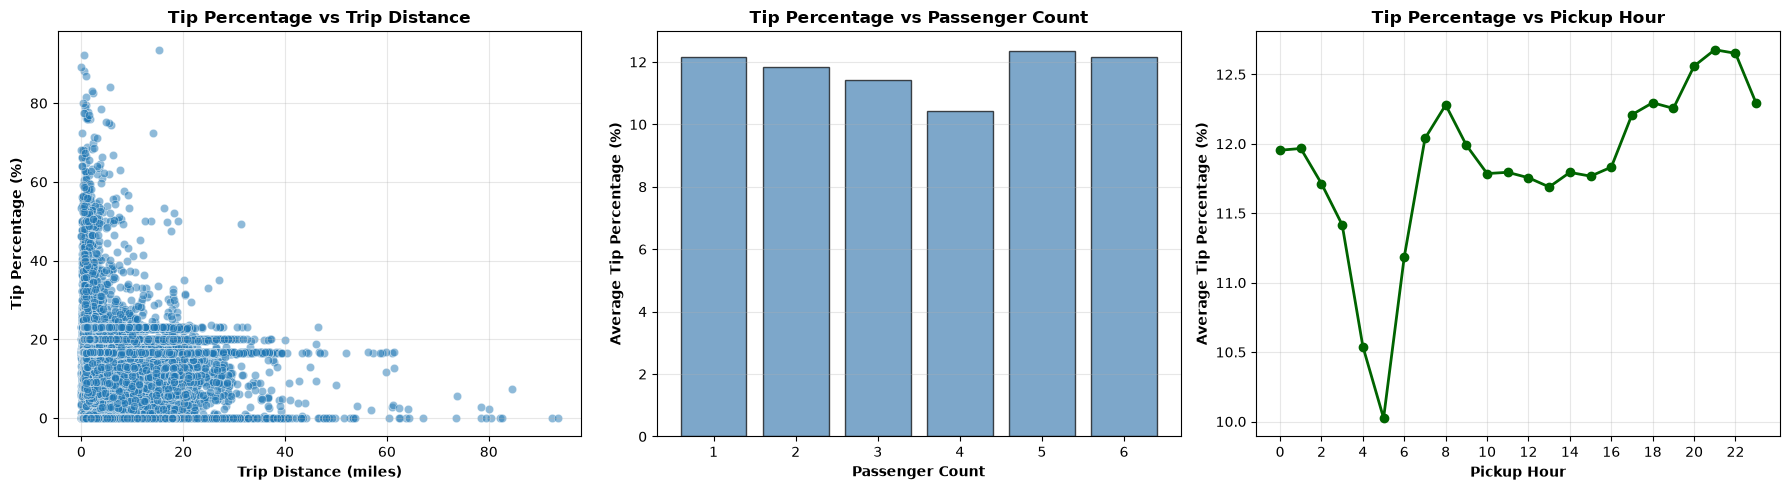

In [81]:
#  Analyze tip percentages based on distances, passenger counts and pickup times

# Filter data and calculate tip percentage
df_tips = df_with_zones[(df_with_zones['trip_distance'] > 0) & (df_with_zones['total_amount'] > 0)].copy()
df_tips['tip_percentage'] = (df_tips['tip_amount'] / df_tips['total_amount']) * 100

# Analyze by trip distance
print("Average Tip Percentage by Trip Distance:")
tip_by_distance = df_tips.groupby(pd.cut(df_tips['trip_distance'], bins=5))['tip_percentage'].agg(['mean', 'count']).reset_index()
print(tip_by_distance)

# Analyze by passenger count
print("\nAverage Tip Percentage by Passenger Count:")
tip_by_passenger = df_tips.groupby('passenger_count')['tip_percentage'].agg(['mean', 'count']).reset_index()
print(tip_by_passenger)

# Analyze by pickup hour
print("\nAverage Tip Percentage by Pickup Hour:")
tip_by_hour = df_tips.groupby('pickup_hour')['tip_percentage'].agg(['mean', 'count']).reset_index()
print(tip_by_hour)

# Visualize tip percentage by distance, passenger count, and pickup hour (side by side)
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Plot 1: Tip Percentage vs Trip Distance
sns.scatterplot(data=df_tips, x='trip_distance', y='tip_percentage', alpha=0.5, ax=axes[0])
axes[0].set_xlabel('Trip Distance (miles)', fontweight='bold')
axes[0].set_ylabel('Tip Percentage (%)', fontweight='bold')
axes[0].set_title('Tip Percentage vs Trip Distance', fontweight='bold')
axes[0].grid(True, alpha=0.3)

# Plot 2: Tip Percentage vs Passenger Count
tip_by_passenger_avg = df_tips.groupby('passenger_count')['tip_percentage'].mean()
axes[1].bar(tip_by_passenger_avg.index, tip_by_passenger_avg.values, color='steelblue', edgecolor='black', alpha=0.7)
axes[1].set_xlabel('Passenger Count', fontweight='bold')
axes[1].set_ylabel('Average Tip Percentage (%)', fontweight='bold')
axes[1].set_title('Tip Percentage vs Passenger Count', fontweight='bold')
axes[1].grid(True, alpha=0.3, axis='y')

# Plot 3: Tip Percentage vs Pickup Hour
tip_by_hour_avg = df_tips.groupby('pickup_hour')['tip_percentage'].mean()
axes[2].plot(tip_by_hour_avg.index, tip_by_hour_avg.values, marker='o', color='darkgreen', linewidth=2, markersize=6)
axes[2].set_xlabel('Pickup Hour', fontweight='bold')
axes[2].set_ylabel('Average Tip Percentage (%)', fontweight='bold')
axes[2].set_title('Tip Percentage vs Pickup Hour', fontweight='bold')
axes[2].grid(True, alpha=0.3)
axes[2].set_xticks(range(0, 24, 2))

plt.tight_layout()
plt.show()

Additional analysis [optional]: Let's try comparing cases of low tips with cases of high tips to find out if we find a clear aspect that drives up the tipping behaviours

In [83]:
# Compare trips with tip percentage < 10% to trips with tip percentage > 25%

# Filter for low and high tip trips
df_tips_analysis = df_with_zones[(df_with_zones['trip_distance'] > 0) & (df_with_zones['total_amount'] > 0)].copy()
df_tips_analysis['tip_percentage'] = (df_tips_analysis['tip_amount'] / df_tips_analysis['total_amount']) * 100

low_tip_trips = df_tips_analysis[df_tips_analysis['tip_percentage'] < 10]
high_tip_trips = df_tips_analysis[df_tips_analysis['tip_percentage'] > 25]

# Compare characteristics
print("Low Tip Trips (< 10%):")
print(f"  Count: {len(low_tip_trips)}")
print(f"  Average trip distance: {low_tip_trips['trip_distance'].mean():.2f} miles")
print(f"  Average passenger count: {low_tip_trips['passenger_count'].mean():.2f}")
print(f"  Most common hour: {low_tip_trips['pickup_hour'].mode().values[0]}")
print(f"  Most common payment type: {low_tip_trips['payment_type'].mode().values[0]}")

print("\nHigh Tip Trips (> 25%):")
print(f"  Count: {len(high_tip_trips)}")
print(f"  Average trip distance: {high_tip_trips['trip_distance'].mean():.2f} miles")
print(f"  Average passenger count: {high_tip_trips['passenger_count'].mean():.2f}")
print(f"  Most common hour: {high_tip_trips['pickup_hour'].mode().values[0]}")
print(f"  Most common payment type: {high_tip_trips['payment_type'].mode().values[0]}")


Low Tip Trips (< 10%):
  Count: 95244
  Average trip distance: 3.68 miles
  Average passenger count: 1.41
  Most common hour: 18
  Most common payment type: 2

High Tip Trips (> 25%):
  Count: 1416
  Average trip distance: 2.30 miles
  Average passenger count: 1.34
  Most common hour: 12
  Most common payment type: 1


**Summary** : Passenger count is almost same for low and high tip. Mostly high tip is paid around 12 hour and low tip is paid around 18 hour and when trip distance is less then probability of high tip being paid is more.

**3.2.14** <font color = red>[3 marks]</font> <br>
Analyse the variation of passenger count across hours and days of the week.

Average Passenger Count by Hour of Day:
    pickup_hour  avg_passenger_count
0             0             1.412494
1             1             1.428466
2             2             1.436729
3             3             1.397458
4             4             1.428125
5             5             1.309252
6             6             1.252708
7             7             1.282570
8             8             1.295739
9             9             1.312311
10           10             1.345861
11           11             1.379908
12           12             1.365782
13           13             1.387743
14           14             1.391877
15           15             1.404958
16           16             1.405537
17           17             1.393320
18           18             1.380257
19           19             1.398949
20           20             1.404643
21           21             1.429603
22           22             1.431988
23           23             1.425516
Average Passenger Count by Day of W

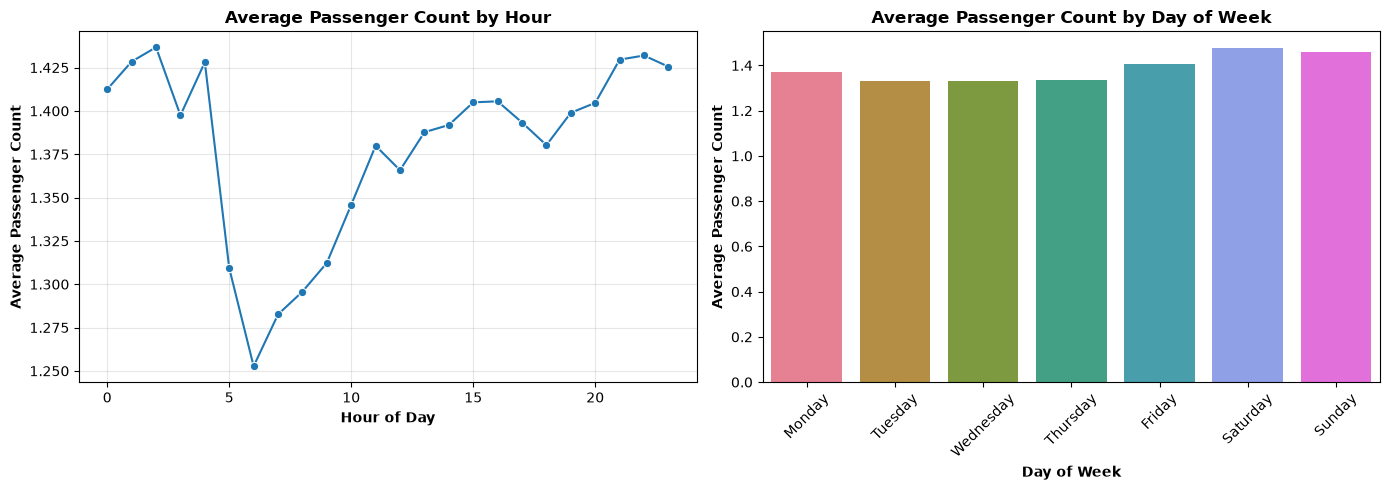

In [86]:
# See how passenger count varies across hours and days

# Average passenger count by hour
passenger_by_hour = df_with_zones.groupby('pickup_hour')['passenger_count'].mean().reset_index(name='avg_passenger_count')

# Average passenger count by day of week
passenger_by_day = df_with_zones.groupby('pickup_day_name')['passenger_count'].mean().reset_index()
day_order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']
passenger_by_day['pickup_day_name'] = pd.Categorical(passenger_by_day['pickup_day_name'],
                                                     categories=day_order, ordered=True)
passenger_by_day = passenger_by_day.sort_values('pickup_day_name')
passenger_by_day.columns = ['day', 'avg_passenger_count']

print("Average Passenger Count by Hour of Day:")
print(passenger_by_hour)

print("Average Passenger Count by Day of Week:")
print(passenger_by_day)

# Visualize
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
# Hour plot
sns.lineplot(data=passenger_by_hour, x='pickup_hour', y='avg_passenger_count', marker='o', ax=axes[0])
axes[0].set_xlabel('Hour of Day', fontweight='bold')
axes[0].set_ylabel('Average Passenger Count', fontweight='bold')
axes[0].set_title('Average Passenger Count by Hour', fontweight='bold')
axes[0].grid(True, alpha=0.3)

# Day plot
sns.barplot(data=passenger_by_day, x='day', y='avg_passenger_count', palette='husl', ax=axes[1])
axes[1].set_xlabel('Day of Week', fontweight='bold')
axes[1].set_ylabel('Average Passenger Count', fontweight='bold')
axes[1].set_title('Average Passenger Count by Day of Week', fontweight='bold')
axes[1].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

**3.2.15** <font color = red>[2 marks]</font> <br>
Analyse the variation of passenger counts across zones

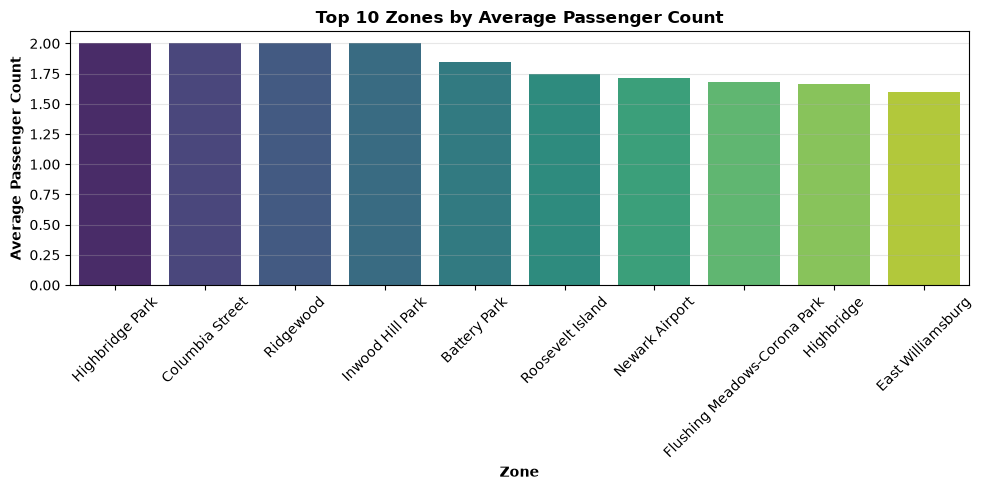

In [88]:
# How does passenger count vary across zones

# Average passenger count by pickup zone
passenger_by_zone = df_with_zones.groupby('zone')['passenger_count'].mean().reset_index(name='avg_passenger_count')
passenger_by_zone = passenger_by_zone.sort_values('avg_passenger_count', ascending=False)

# Visualize top zones
plt.figure(figsize=(10, 5))
sns.barplot(data=passenger_by_zone.head(10), x='zone', y='avg_passenger_count', palette='viridis')
plt.xlabel('Zone', fontweight='bold')
plt.ylabel('Average Passenger Count', fontweight='bold')
plt.title('Top 10 Zones by Average Passenger Count', fontweight='bold')
plt.xticks(rotation=45)
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

In [89]:
# For a more detailed analysis, add average passenger count to zones_with_trips GeoDataFrame

# Calculate average passenger count by zone
passenger_by_zone_detailed = df_with_zones.groupby('zone')['passenger_count'].mean().reset_index()
passenger_by_zone_detailed.columns = ['zone', 'avg_passenger_count']

# Merge with zones_with_trips
zones_with_trips['avg_passenger_count'] = zones_with_trips['zone'].map(
    dict(zip(passenger_by_zone_detailed['zone'], passenger_by_zone_detailed['avg_passenger_count']))
)

# Display zones sorted by average passenger count
zones_sorted_by_passengers = zones_with_trips.sort_values('avg_passenger_count', ascending=False)
print("Top 10 Zones by Average Passenger Count:")
print(zones_sorted_by_passengers[['zone', 'trip_count', 'avg_passenger_count']].head(10))

Top 10 Zones by Average Passenger Count:
                             zone  trip_count  avg_passenger_count
53                Columbia Street         3.0             2.000000
119               Highbridge Park         3.0             2.000000
127              Inwood Hill Park         1.0             2.000000
197                     Ridgewood         4.0             2.000000
11                   Battery Park       136.0             1.845588
201              Roosevelt Island        16.0             1.750000
0                  Newark Airport        35.0             1.714286
92   Flushing Meadows-Corona Park        63.0             1.682540
118                    Highbridge         9.0             1.666667
79              East Williamsburg        40.0             1.600000


Find out how often surcharges/extra charges are applied to understand their prevalance

**3.2.16** <font color = red>[5 marks]</font> <br>
Analyse the pickup/dropoff zones or times when extra charges are applied more frequently

Surcharge Application Frequency:
Trips with MTA tax: 287491 (99.07%)
Trips with improvement surcharge: 290085 (99.97%)
Trips with congestion surcharge: 268288 (92.46%)
Trips with airport fee: 25390 (8.75%)
Congestion Surcharge by Pickup Hour:
    hour  congestion_surcharge_rate
0      0                  91.223503
1      1                  93.039956
2      2                  94.921090
3      3                  93.728814
4      4                  88.180113
5      5                  78.390368
6      6                  84.708613
7      7                  89.594266
8      8                  91.932789
9      9                  92.020886
10    10                  92.386649
11    11                  93.160801
12    12                  93.285508
13    13                  92.901007
14    14                  92.555719
15    15                  92.288284
16    16                  92.430633
17    17                  93.335735
18    18                  94.013777
19    19                  93.458248
2

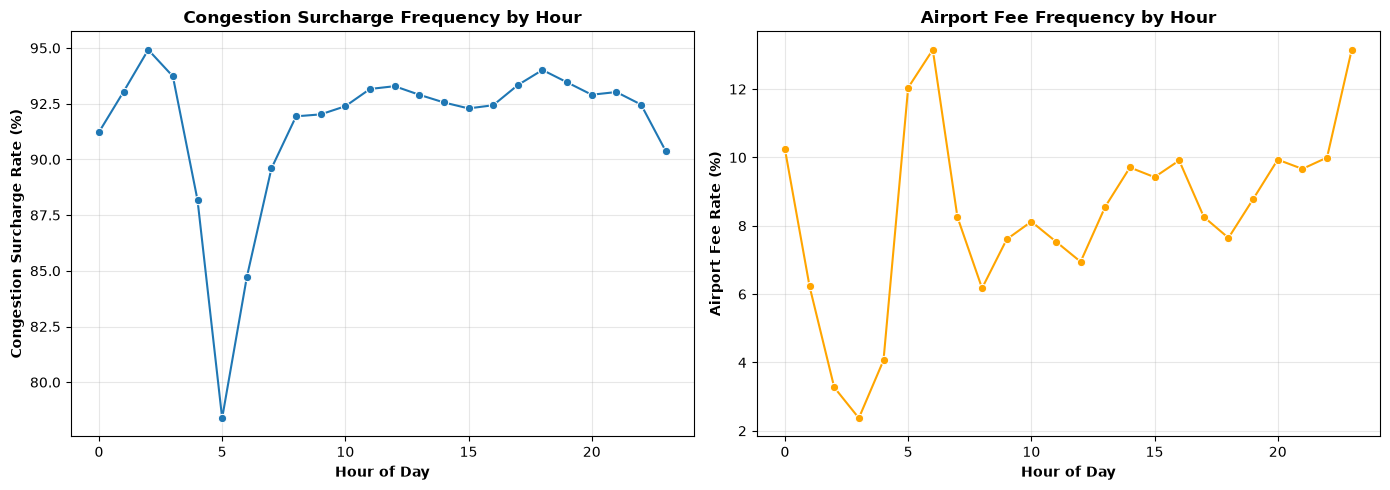

In [91]:
# How often is each surcharge applied?

# Analyze surcharge frequencies
print("Surcharge Application Frequency:")
print(f"Trips with MTA tax: {(df['mta_tax'] > 0).sum()} ({(df['mta_tax'] > 0).sum() / len(df) * 100:.2f}%)")
print(f"Trips with improvement surcharge: {(df['improvement_surcharge'] > 0).sum()} ({(df['improvement_surcharge'] > 0).sum() / len(df) * 100:.2f}%)")
print(f"Trips with congestion surcharge: {(df['congestion_surcharge'] > 0).sum()} ({(df['congestion_surcharge'] > 0).sum() / len(df) * 100:.2f}%)")
print(f"Trips with airport fee: {(df['airport_fee'] > 0).sum()} ({(df['airport_fee'] > 0).sum() / len(df) * 100:.2f}%)")

# Analyze surcharges by hour
df['pickup_hour'] = df['tpep_pickup_datetime'].dt.hour

print("Congestion Surcharge by Pickup Hour:")
congestion_by_hour = df.groupby('pickup_hour').apply(lambda x: (x['congestion_surcharge'] > 0).sum() / len(x) * 100).reset_index()
congestion_by_hour.columns = ['hour', 'congestion_surcharge_rate']
print(congestion_by_hour)

print("Airport Fee by Pickup Hour:")
airport_by_hour = df.groupby('pickup_hour').apply(lambda x: (x['airport_fee'] > 0).sum() / len(x) * 100).reset_index()
airport_by_hour.columns = ['hour', 'airport_fee_rate']
print(airport_by_hour)

# Analyze surcharges by zone (if available)
if 'zone' in df_with_zones.columns:
    print("Congestion Surcharge by Pickup Zone (Top 10):")
    congestion_by_zone = df_with_zones.groupby('zone').apply(
        lambda x: (x['congestion_surcharge'] > 0).sum() / len(x) * 100 if len(x) > 0 else 0
    ).sort_values(ascending=False).reset_index()
    congestion_by_zone.columns = ['zone', 'congestion_surcharge_rate']
    print(congestion_by_zone.head(10))

# Visualize surcharge frequency by hour
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.lineplot(data=congestion_by_hour, x='hour', y='congestion_surcharge_rate', marker='o', ax=axes[0])
axes[0].set_xlabel('Hour of Day', fontweight='bold')
axes[0].set_ylabel('Congestion Surcharge Rate (%)', fontweight='bold')
axes[0].set_title('Congestion Surcharge Frequency by Hour', fontweight='bold')
axes[0].grid(True, alpha=0.3)

sns.lineplot(data=airport_by_hour, x='hour', y='airport_fee_rate', marker='o', color='orange', ax=axes[1])
axes[1].set_xlabel('Hour of Day', fontweight='bold')
axes[1].set_ylabel('Airport Fee Rate (%)', fontweight='bold')
axes[1].set_title('Airport Fee Frequency by Hour', fontweight='bold')
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

## **4** Conclusion
<font color = red>[15 marks]</font> <br>

### **4.1** Final Insights and Recommendations
<font color = red>[15 marks]</font> <br>

Conclude your analyses here. Include all the outcomes you found based on the analysis.

Based on the insights, frame a concluding story explaining suitable parameters such as location, time of the day, day of the week etc. to be kept in mind while devising a strategy to meet customer demand and optimise supply.

**4.1.1** <font color = red>[5 marks]</font> <br>
Recommendations to optimize routing and dispatching based on demand patterns and operational inefficiencies

**Recommendations to Improve Routing and Dispatching**

**1. Peak Hours: 4 PM - 9 PM**
* Increase the fleet by **30-35%** during peak hours.
* Keep more vehicles in **Manhattan CBD and major transportation hubs**.
* The busiest time is around **6 PM**, with about **20,614 pickups**.
* Start predicting demand about **2 hours before the peak**.
* Manage driver shifts so enough drivers are available during busy periods.
* Achieve reduction in customer wait time below with help of above metrics

**2. Off-Peak Hours: 10 AM - 4 PM and Early Morning**
* Use fewer vehicles when demand is low.
* Keep only about **10-15% of the fleet** available during very low-demand periods.
* Schedule any maintenance or breaks during this period to achieve operational efficiencies

**3. Weekday vs Weekend**
**Weekdays**
* Weekdays have about **20-25% higher demand** than weekends.
* **Thursday** has a high demand, with about **45,546 pickups**.
* During the morning (**6 AM - 9 AM**), keep about **50% of vehicles** near residential and business areas.
* During the evening (**4 PM - 7 PM**), move more vehicles toward the **CBD and business areas**.
**Weekends**
* Keep about more taxis near:
  * Entertainment areas
  * Shopping areas

**4. Route Optimization**
* Find routes where the average speed is low during peak hours
* For each route, find **2-3 alternative routes**.

**5. Zone-Based Dispatching**
**High Pickup Areas:**
* **JFK Airport** - 15,326 pickups (highest volume)
* **Penn Station/Madison Square West** - 10,193 pickups
* **Grand Central Terminal** - Major transit hub with consistent demand
* **Manhattan CBD** - Concentrated business and commercial activities

**High Drop-Off Areas:**
* Manhattan CBD (central business district) - Primary destination for morning commutes
* Penn Station/Grand Central - Major transit connection points
* Airports (JFK, LaGuardia, Newark) - Destination for long-distance trips
* Upper East/West Side - Residential areas receiving evening drop-offs
* Keep more fleet in high-demand areas.
* Move vehicles to zones where there are more pickups than drop-offs.

**4.1.2** <font color = red>[5 marks]</font> <br>

Suggestions on strategically positioning cabs across different zones to make best use of insights uncovered by analysing trip trends across time, days and months.

**Zone-Based Fleet Positioning Strategy**

**1. High-Demand Zones**
Important high-demand areas include:
* Manhattan CBD
* JFK Airport
* Penn Station
* Grand Central

**Strategy**
* Keep most of the fleets in these areas during peak hours.
* Peak hours are **7-9 AM** and **5-7 PM**.
* Focus on areas where there are many customers and high-value trips.
**Expected Results**
* Reduce customer wait time 
* Increase vehicle utilization
* Increase average fare and number of trips.

**2. Outer Boroughs: Queens and Brooklyn**
**Strategy**
* Allocate about **30-35% of the fleet** to these areas.
* Keep vehicles available throughout the day.
* Demand may be more stable because there is less competition from other services.
* During evening peak hours (**5-7 PM**), move more vehicles to high-demand areas when needed.

**3. Airport Zones**
Important airport zones include:
* JFK
* LaGuardia
* Newark
**Strategy**
* Keep around **10-15% of the total fleet** for airport trips.
* Airport trips are usually longer and have higher fares.
* However, the number of trips is lower compared with busy city areas.
* Pre-arrange drivers for airport trips.
* This helps reduce the time vehicles spend waiting without passengers.

**4. Time-Based Fleet Positioning**
The location of vehicles should change based on the time of day.
**Morning: 6-9 AM**
* Keep about **50% of the fleet** near:
  * Residential areas
  * Train stations
  * Transit stations
* Main demand comes from people travelling to work.
**Midday: 10 AM-3 PM**
* Spread vehicles across the CBD and other service areas.
* Use a lower vehicle density of around **20% of the baseline fleet**.
**Evening: 4-7 PM**
* Increase the number of vehicles in:
  * CBD
  * Airport connections
  * Other high-demand areas
* Keep around **45% of the fleet** in these areas.
**Night: 8 PM-5 AM**
* Use a smaller fleet.
* Keep vehicles ready for sudden increases in demand.
* Focus mainly on:
  * Entertainment areas
  * Bars
  * Night-life districts

**5. Pickup and Drop-Off Ratio**
Use the **pickup-to-dropoff ratio** to decide where vehicles should be moved.
**High Pickup Areas**
* **JFK Airport** (15,326 pickups) - Airport terminal pickups create concentrated demand
* **Penn Station/Madison Sq West** (10,193 pickups) - Major transit connection hub  
* **Grand Central Terminal** - Business and commuter pickups during morning hours
* **Times Square/Port Authority** - Entertainment and tourism-driven pickups
* These areas need more vehicles.
* Encourage drivers to move toward these areas.
* Use incentives when necessary ($2-5 bonus for completing pickups in low-supply zones).

**High Drop-Off Areas**
* **Manhattan CBD (Midtown/Downtown)** - Primary destination for morning commutes, office locations
* **Upper East/West Side** - Residential areas receiving return evening trips
* **Penn Station/Grand Central** - Transit connection points for onward travel
* **Airports (JFK, LaGuardia)** - Long-distance trip destinations
* Many vehicles arrive here with passengers.
* Make sure enough vehicles are available for the next trip.
* Move empty vehicles to nearby areas where demand is higher.
* Consider pre-positioning based on time-of-day demand patterns.


**4.1.3** <font color = red>[5 marks]</font> <br>
Propose data-driven adjustments to the pricing strategy to maximize revenue while maintaining competitive rates with other vendors.

**Dynamic Pricing by Time of Day**

**1. Peak Hours: 7-9 AM and 5-7 PM**
**Strategy**
* There is a strong relationship between **trip distance and fare**.
* The correlation between distance and fare is **0.95**.
* Demand is much higher during peak hour
* Use surge pricing during peak hours and having longer trip distance.

**2. Off-Peak Hours: 10 AM-3 PM**
**Strategy**
* Reduce the base fare by around **5-10%**.
* Lower prices can attract customers who are more sensitive to price.
* Demand is lower during these hours, so discounts can help increase the number of trips.

**3. Night Hours: 11 PM-5 AM**
**Strategy**
* Use **10-20% higher pricing** during night hours.
* Only about **23.5% of total revenue** comes from night hours.
* Night demand is lower, but there may be an opportunity to charge a higher price.
* Fewer available vehicles and fewer competitors can support higher prices.

**4. Zone-Based Pricing**
Different areas can have different pricing based on demand.
**High-Demand Zones**
Examples:
* JFK Airport: **15,326 pickups**
* Penn Station: **10,193 pickups**
* Grand Central
* Manhattan CBD
**Strategy**
* Increase surcharge price to these zone and it to the base fare.
* These areas have high demand and limited vehicle supply.
* Higher prices can help balance demand and supply.

**Medium-Demand Zones**
Examples:
* Queens
* Brooklyn
**Strategy**
* Give little discount during off-peak hours.
* Add some premium during peak hours.


**5. Distance-Based Pricing**
Pricing can also depend on trip distance.
**Strategy**
* Use higher prices for short trips.
* Use standard pricing for medium trips.
* Offer a lower price per mile for longer trips to encourage more long-distance bookings.

**6. Passenger Count Pricing**
* There is almost no relationship between **number of passengers and fare**.
* The correlation is only **0.04**.
* This means the current fare does not change much when more passengers are added.
**Strategy**
* Add a fixed surcharge for each additional passenger.
* This can generate additional revenue without making the main fare much more expensive.

**7. Payment Method Strategy**
* **Credit card payments** are the most common payment method.
* Offer a **5% discount for cash payments** if the goal is to increase cash usage.
* There is a positive relationship between **trip distance and tips**.
* The correlation between distance and tips is **0.59**.
**Strategy**
* Encourage card payments for longer trips where tips may be higher.
* Use payment incentives carefully to balance convenience and revenue.

**8. Vendor-Based Optimization**

Different vendors may charge different fares for similar trips.
**Strategy**
* Compare fares across vendors for different distance ranges.
* Give better-performing vendors more favorable commission rates.
* Match high-revenue trips with the best vendor and vehicle combinations.
* Use historical trip data to identify the best combinations.


